In [ ]:
#Install Packages, mount Drive, and check Limits
!pip install -q geopandas rasterio rasterstats pyarrow folium mapclassify pyogrio mercantile scipy
!apt-get -qq install -y p7zip-full p7zip-rar
from google.colab import drive
drive.mount('/content/drive')
!df -h /content
!free -h

Selecting previously unselected package 7zip-rar.
(Reading database ... 122807 files and directories currently installed.)
Preparing to unpack .../7zip-rar_23.01-4_amd64.deb ...
Unpacking 7zip-rar (23.01-4) ...
Selecting previously unselected package p7zip-rar.
Preparing to unpack .../p7zip-rar_16.02+transitional.1_all.deb ...
Unpacking p7zip-rar (16.02+transitional.1) ...
Setting up 7zip-rar (23.01-4) ...
Setting up p7zip-rar (16.02+transitional.1) ...
Mounted at /content/drive
Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   21G   88G  20% /
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.1Gi       8.1Gi       2.2Mi       3.8Gi        11Gi
Swap:             0B          0B          0B


In [ ]:
#Extraxt Files unto the runtime

!7z x /content/drive/MyDrive/digital-divide/raw/onsset_data.rar -o/content/onsset
!find /content/onsset -type f | head -50


7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576

Scanning the drive for archives:
  0M Scan /content/drive/MyDrive/digital-divide/raw/                                                    1 file, 1861223244 bytes (1776 MiB)

Extracting archive: /content/drive/MyDrive/digital-divide/raw/onsset_data.rar
 14% 100 Open             --
Path = /content/drive/MyDrive/digital-divide/raw/onsset_data.rar
Type = Rar
Physical Size = 1861223244
Solid = -
Blocks = 185
Multivolume = -
Volumes = 1

  5%/content/onsset/Data used in GIS-based rural electrification planning study on Nigeria using OnSSET/Administrative boundaries/AEDC_area.prj
/content/onsset/Data used in GIS-based rural electrification planning study on Nigeria using OnSSET/Administrative boundaries/AEDC_area.cpg
/content/onsset/Data used

In [ ]:
#Checking if 5% extraction was truly cutoff

!du -sh /content/onsset
!find /content/onsset -type f | wc -l

24K	/content/onsset
4


In [ ]:
#Fixing the 5% cutoff extraction

!apt-get -qq install -y p7zip-full p7zip-rar
from google.colab import drive
drive.mount('/content/drive')

!cp /content/drive/MyDrive/digital-divide/raw/onsset_data.rar /content/onsset_data.rar
!ls -lh /content/onsset_data.rar
!7z x /content/onsset_data.rar -o/content/onsset -y -aoa | tail -5
!du -sh /content/onsset
!find /content/onsset -type f | wc -l

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
-rw------- 1 root root 1.8G Oct 19 20:03 /content/onsset_data.rar

Scanning the drive for archives:
1 file, 1861223244 bytes (1776 MiB)

Extracting archive: /content/onsset_data.rar
24K	/content/onsset
4


In [ ]:
!7z l /content/onsset_data.rar -bsp0 | tail -15
print("-----")
!7z t /content/onsset_data.rar -bsp0 | tail -25

2025-04-22 22:16:01 D....            0            0  Data used in GIS-based rural electrification planning study on Nigeria using OnSSET/Land Cover
2025-04-22 22:16:02 D....            0            0  Data used in GIS-based rural electrification planning study on Nigeria using OnSSET/Medium-voltage lines (Existing)
2022-06-02 07:44:16 D....            0            0  Data used in GIS-based rural electrification planning study on Nigeria using OnSSET/Medium-voltage lines (Planned)
2025-04-22 22:16:02 D....            0            0  Data used in GIS-based rural electrification planning study on Nigeria using OnSSET/Nigeria_pop_clusters
2025-04-22 22:16:03 D....            0            0  Data used in GIS-based rural electrification planning study on Nigeria using OnSSET/Night-time lights
2025-04-22 22:16:03 D....            0            0  Data used in GIS-based rural electrification planning study on Nigeria using OnSSET/Polling Units - KEDCo
2025-04-22 22:16:03 D....            0     

In [ ]:
!apt-get -qq install -y unrar
!unrar t -idq /content/onsset_data.rar; echo "exit code: $?"

exit code: 0


In [ ]:
!7z l /content/onsset_data.rar -bsp0 > /content/listing.txt
import re
lines = [l for l in open('/content/listing.txt') if re.match(r'\d{4}-\d\d-\d\d', l) and ' D....' not in l]
for l in lines:
    parts = l.split(None, 5)
    size_mb = int(parts[3]) / 1e6
    path = parts[5].strip().replace("Data used in GIS-based rural electrification planning study on Nigeria using OnSSET/", "")
    print(f"{size_mb:9.1f} MB  {path}")

      0.0 MB  Administrative boundaries/AEDC_area.cpg
      0.0 MB  Administrative boundaries/AEDC_area.dbf
      0.0 MB  Administrative boundaries/AEDC_area.prj
      0.0 MB  Administrative boundaries/AEDC_area.shp
      0.0 MB  Administrative boundaries/AEDC_area.shx
      0.0 MB  Administrative boundaries/AEDC_Coverage_Area.rar
      0.0 MB  Administrative boundaries/Disco_Coverage_Areas/DISCOs_FRANCHISE_AREA.cpg
      0.0 MB  Administrative boundaries/Disco_Coverage_Areas/DISCOs_FRANCHISE_AREA.dbf
      0.0 MB  Administrative boundaries/Disco_Coverage_Areas/DISCOs_FRANCHISE_AREA.prj
      0.4 MB  Administrative boundaries/Disco_Coverage_Areas/DISCOs_FRANCHISE_AREA.shp
      0.0 MB  Administrative boundaries/Disco_Coverage_Areas/DISCOs_FRANCHISE_AREA.shx
      0.3 MB  Administrative boundaries/Disco_Coverage_Areas.zip
      0.0 MB  Administrative boundaries/gadm40_NGA_shp/gadm40_NGA_0.cpg
      0.0 MB  Administrative boundaries/gadm40_NGA_shp/gadm40_NGA_0.dbf
      0.0 MB  Administr

In [ ]:
!unrar x -idq -o+ -x"*Settlement clusters*" -x"*Nigeria_pop_clusters*" -x"*Wind speed*" /content/onsset_data.rar /content/onsset/
!du -sh /content/onsset
!find /content/onsset -type f | wc -l

5.2G	/content/onsset
154


In [ ]:
import os, geopandas as gpd, rasterio
ROOT = "/content/onsset/Data used in GIS-based rural electrification planning study on Nigeria using OnSSET"
LGA  = f"{ROOT}/Administrative boundaries/gadm40_NGA_shp/gadm40_NGA_2.shp"
POP  = f"{ROOT}/Population/nga_ppp_2020.tif"
NTL  = f"{ROOT}/Night-time lights/nightlights.tif"
HLTH = f"{ROOT}/Health facilities/health-care-facilities-primary-secondary-and-tertiary.geojson"

lga = gpd.read_file(LGA)
print("LGAs:", len(lga), "| CRS:", lga.crs, "| all valid:", lga.is_valid.all())
print(lga.columns.tolist())

for p in (POP, NTL):
    with rasterio.open(p) as s:
        print(os.path.basename(p), "| CRS:", s.crs, "| res:", s.res, "| shape:", s.shape,
              "| nodata:", s.nodata, "| dtype:", s.dtypes[0])

h = gpd.read_file(HLTH)
print("Health:", len(h), h.geometry.geom_type.unique(), h.columns.tolist()[:15])

!find "{ROOT}/Educational institutions" -iname "*primary*"

LGAs: 775 | CRS: EPSG:4326 | all valid: True
['ID_0', 'COUNTRY', 'NAME_1', 'NL_NAME_1', 'ID_2', 'NAME_2', 'VARNAME_2', 'NL_NAME_2', 'TYPE_2', 'ENGTYPE_2', 'CC_2', 'HASC_2', 'geometry']
nga_ppp_2020.tif | CRS: EPSG:4326 | res: (0.0008333333299798793, 0.0008333333299844101) | shape: (11546, 14413) | nodata: -99999.0 | dtype: float32
nightlights.tif | CRS: EPSG:4326 | res: (0.004166545593337959, 0.00416699504980511) | shape: (2309, 2882) | nodata: 3.4028234663852886e+38 | dtype: float32
Health: 49329 ['Point'] ['id', 'latitude', 'longitude', 'contact_phone', 'contact_name', 'ri_service_status', 'cce_quantity', 'cce_available', 'cce_lastupdated', 'category', 'global_id', 'name', 'alternate_name', 'functional_status', 'type']
/content/onsset/Data used in GIS-based rural electrification planning study on Nigeria using OnSSET/Educational institutions/nigerian-primary-schools.shp.zip
/content/onsset/Data used in GIS-based rural electrification planning study on Nigeria using OnSSET/Educational

In [ ]:
import numpy as np, zipfile, glob, re

# 1. the 775th LGA
print(lga.groupby(["TYPE_2", "ENGTYPE_2"]).size())
print(lga.NAME_2.duplicated().sum(), "duplicate NAME_2 values")
print(lga[lga.TYPE_2.isna() | ~lga.TYPE_2.isin(lga.TYPE_2.value_counts().index[:1])][["NAME_1", "NAME_2", "TYPE_2"]])

# 2. population: is it a count?
with rasterio.open(POP) as s:
    a = s.read(1, masked=True)
print("pop sum:", float(a.sum()), "| max cell:", float(a.max()), "| populated cells:", int((a > 0).sum()))

# 3. night lights: valid-value distribution + any metadata
with rasterio.open(NTL) as s:
    n = s.read(1, masked=True)
    print(s.tags(), s.descriptions)
v = n.compressed()
print("NTL valid cells:", v.size, "| percentiles 10/25/50/75/90/99:", np.percentile(v, [10, 25, 50, 75, 90, 99]).round(2), "| share == 0:", round(float((v == 0).mean()), 3))
print(open(NTL + ".aux.xml").read()[:600])

# 4. health facilities
for c in ["category", "type", "functional_status"]:
    print(h[c].value_counts(dropna=False).head(8), "\n")
print("missing/zero coords:", int(h.geometry.is_empty.sum()), "| duplicated ids:", int(h.id.duplicated().sum()))

# 5. primary schools: unzip and open
z = f"{ROOT}/Educational institutions/nigerian-primary-schools.shp.zip"
zipfile.ZipFile(z).extractall("/content/primary")
shp = glob.glob("/content/primary/**/*.shp", recursive=True)
print(shp)
ps = gpd.read_file(shp[0])
print("Primary schools:", len(ps), ps.crs, ps.geometry.geom_type.unique(), ps.columns.tolist())

TYPE_2           ENGTYPE_2      
Local Authority  Local Authority    774
Water body       Water body           1
dtype: int64
5 duplicate NAME_2 values
    NAME_1     NAME_2      TYPE_2
159  Borno  Lake Chad  Water body
pop sum: 216682016.0 | max cell: 1068.634765625 | populated cells: 107067285
{'AREA_OR_POINT': 'Area'} (None,)
NTL valid cells: 4310610 | percentiles 10/25/50/75/90/99: [0.  0.  0.  0.  0.  2.4] | share == 0: 0.969
<PAMDataset>
  <PAMRasterBand band="1">
    <Metadata>
      <MDI key="STATISTICS_MAXIMUM">807.66296386719</MDI>
      <MDI key="STATISTICS_MEAN">0.13510915255583</MDI>
      <MDI key="STATISTICS_MINIMUM">0</MDI>
      <MDI key="STATISTICS_STDDEV">4.0244788986298</MDI>
    </Metadata>
  </PAMRasterBand>
</PAMDataset>

category
Primary Health Center    28880
Dispensary                8628
Maternity Home            4424
Private Non Profit        1207
Primary Health Clinic     1156
Medical Center             956
Specialist Hospital        701
General Hospital   

IndexError: list index out of range

In [ ]:
# LGAs
lga = lga[lga.TYPE_2 != "Water body"].copy()
lga["lga_id"] = lga.ID_2
print(len(lga), "| ID_2 unique:", lga.ID_2.is_unique)
print(lga[lga.NAME_2.duplicated(keep=False)].sort_values("NAME_2")[["NAME_1", "NAME_2", "ID_2"]])

# night lights: the non-zero part (v is from the previous cell)
nz = v[v > 0]
print("non-zero cells:", nz.size, "| percentiles 5/25/50/75/95/99/99.9:",
      np.percentile(nz, [5, 25, 50, 75, 95, 99, 99.9]).round(2))
for c in (0.1, 0.5, 1, 2, 5):
    print(f"cells >= {c}: {(v >= c).sum():,}  ({(v >= c).mean()*100:.2f}% of valid cells)")

774 | ID_2 unique: True
        NAME_1    NAME_2         ID_2
472       Kogi     Bassa   NGA.23.4_1
666    Plateau     Bassa   NGA.32.2_1
494      Kwara  Ifelodun   NGA.24.5_1
617       Osun  Ifelodun  NGA.30.16_1
498      Kwara  Irepodun   NGA.24.9_1
621       Osun  Irepodun  NGA.30.20_1
131      Benue       Obi   NGA.7.14_1
536  Nassarawa       Obi  NGA.26.11_1
525      Lagos  Surulere  NGA.25.20_1
664        Oyo  Surulere  NGA.31.33_1
non-zero cells: 133788 | percentiles 5/25/50/75/95/99/99.9: [1.0000e-01 3.3000e-01 1.0400e+00 3.5000e+00 1.4460e+01 4.6600e+01
 4.0857e+02]
cells >= 0.1: 126,969  (2.95% of valid cells)
cells >= 0.5: 88,761  (2.06% of valid cells)
cells >= 1: 68,114  (1.58% of valid cells)
cells >= 2: 48,056  (1.11% of valid cells)
cells >= 5: 24,307  (0.56% of valid cells)


In [ ]:
import pyogrio, os
EDU = f"{ROOT}/Educational institutions"

# primary schools: attributes only, since there is no geometry file
d = f"{EDU}/nigerian-primary-schools.shp"
print(os.listdir(d), os.listdir("/content/primary"))
ps = pyogrio.read_dataframe(f"{d}/nigerian-primary-schools.dbf")
print("Primary:", len(ps), type(ps).__name__); print(ps.columns.tolist()); print(ps.head(3))

# secondary and tertiary
for name in ("secondary-schools", "tertiary-schools"):
    g = gpd.read_file(f"{EDU}/{name}.geojson")
    print(name, len(g), g.crs, g.geometry.geom_type.unique().tolist(), g.columns.tolist()[:12])

# where did the population raster come from?
!pip install -q python-docx
import docx
dd = docx.Document(f"{ROOT}/Population/Link to population raster.docx")
print("\n".join(p.text for p in dd.paragraphs if p.text.strip()))
for r in dd.part.rels.values():
    if "hyperlink" in r.reltype: print(r.target_ref)

# the Ookla files
!ls -lh /content/drive/MyDrive/digital-divide/raw/

['nigerian-primary-schools.shx', 'nigerian-primary-schools.dbf', 'nigerian-primary-schools.prj'] ['nigerian-primary-schools.shx', 'nigerian-primary-schools.dbf', 'nigerian-primary-schools.prj']
Primary: 107670 DataFrame
['id', 'global_id', 'name', 'ward_code', 'number_of_', 'number_o_1', 'sub_type', 'management', 'education_', 'category', 'timestamp', 'lga_name', 'lga_code', 'state_code', 'state_name']
       id                             global_id  \
0  958071  2f80f0e5-9801-46ba-b8cd-b0663413bff1   
1  958070  7b95def3-9958-48fb-8513-b7584cf2507c   
2  958069  c963dfbe-c0ca-4b97-96b7-29a355687a85   

                              name ward_code  number_of_  number_o_1  \
0                Islamic Education    JI1104         NaN         NaN   
1  Islamic Educational Institution    JI1109         NaN         NaN   
2                  Islamiya School    JI0609         NaN         NaN   

   sub_type   management education_ category  timestamp lga_name lga_code  \
0  Standard  Faith Base

In [ ]:
import pyogrio, geopandas as gpd
OOK = "/content/drive/MyDrive/digital-divide/raw/Nigeria Ookla.gpkg"
print(pyogrio.list_layers(OOK))

o = gpd.read_file(OOK)
print(len(o), "| CRS:", o.crs, "| geometry:", o.geom_type.unique().tolist())
print(o.dtypes)
print(o.drop(columns="geometry").head(5).T)
print(o.drop(columns="geometry").describe().T)
print("bounds:", o.total_bounds)
print(o.to_crs(32632).geometry.area.describe() / 1e6, "(km^2 per tile)")

[['Nigeria Ookla' 'MultiPolygon']
 ['nigeria_ookla' 'MultiPolygon']]


/usr/local/lib/python3.13/dist-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'Nigeria Ookla.gpkg': 'Nigeria Ookla' (default), 'nigeria_ookla'. Specify layer parameter to avoid this warning.
  result = read_func(


9234 | CRS: None | geometry: ['MultiPolygon']
quadkey              object
tile                 object
tile_x              float64
tile_y              float64
avg_d_kbps            int64
avg_u_kbps            int64
avg_lat_ms            int64
avg_lat_down_ms     float64
avg_lat_up_ms       float64
tests                 int64
devices               int64
geometry           geometry
dtype: object
                                                                 0  \
quadkey                                           1222230123102111   
tile             POLYGON((7.5970458984375 4.5216663426148, 7.60...   
tile_x                                                      7.5998   
tile_y                                                      4.5189   
avg_d_kbps                                                    3874   
avg_u_kbps                                                    4699   
avg_lat_ms                                                      53   
avg_lat_down_ms                             

ValueError: Cannot transform naive geometries.  Please set a crs on the object first.

In [ ]:
o1 = gpd.read_file(OOK, layer="Nigeria Ookla").set_crs(4326)
o2 = gpd.read_file(OOK, layer="nigeria_ookla")
print("rows:", len(o1), len(o2), "| CRS of 2nd layer:", o2.crs)
print("same quadkeys:", set(o1.quadkey) == set(o2.quadkey), "| duplicate quadkeys:", o1.quadkey.duplicated().sum())
print("same columns:", list(o1.columns) == list(o2.columns))

o = o1.drop(columns="tile")
op = o.to_crs(32632)
print((op.area / 1e6).describe(), "(km^2 per tile)")

cen = op.centroid.to_crs(4326)
print("centroid vs tile_x/y max offset (deg):", (cen.x - o.tile_x).abs().max(), (cen.y - o.tile_y).abs().max())

for k in (1, 2, 3, 5, 10):
    m = o.tests >= k
    print(f"tests>={k}: {m.sum():,} tiles ({m.mean()*100:.1f}%), {o.loc[m,'tests'].sum():,} tests")

oc = o.copy(); oc["geometry"] = cen
j = gpd.sjoin(oc, lga[["lga_id", "geometry"]], predicate="within")
print("tiles matched to an LGA:", len(j), "of", len(o), "| duplicates:", j.index.duplicated().sum())
print("LGAs with >=1 tile:", j.lga_id.nunique(), "of 774")
print("LGAs with >=1 tile at tests>=3:", j[j.tests >= 3].lga_id.nunique(), "of 774")

rows: 9234 9234 | CRS of 2nd layer: EPSG:4326
same quadkeys: True | duplicate quadkeys: 0
same columns: True
count    9234.000000
mean        0.365036
std         0.015828
min         0.001627
25%         0.362548
50%         0.367803
75%         0.369060
max         0.370741
dtype: float64 (km^2 per tile)
centroid vs tile_x/y max offset (deg): 0.0026025910377467376 0.002592558223141417
tests>=1: 9,234 tiles (100.0%), 42,838 tests
tests>=2: 5,329 tiles (57.7%), 38,933 tests
tests>=3: 3,727 tiles (40.4%), 35,729 tests
tests>=5: 2,227 tiles (24.1%), 30,623 tests
tests>=10: 962 tiles (10.4%), 22,359 tests
tiles matched to an LGA: 9204 of 9234 | duplicates: 0
LGAs with >=1 tile: 529 of 774
LGAs with >=1 tile at tests>=3: 316 of 774


In [ ]:
import shutil, os
D = "/content/drive/MyDrive/digital-divide"
L = f"{D}/interim/layers"; os.makedirs(L, exist_ok=True)

keep = [
 "Administrative boundaries/gadm40_NGA_shp",
 "Population/nga_ppp_2020.tif",
 "Population/Link to population raster.docx",
 "Night-time lights/nightlights.tif",
 "Night-time lights/nightlights.tif.aux.xml",
 "Health facilities/health-care-facilities-primary-secondary-and-tertiary.geojson",
 "Educational institutions/secondary-schools.geojson",
 "Educational institutions/tertiary-schools.geojson",
 "High-voltage lines (Existing)/all_transmission_line (1)",
 "Travel hours/Traveltime.tif",
]
for k in keep:
    src = f"{ROOT}/{k}"; dst = f"{L}/{os.path.basename(k)}"
    if os.path.isdir(src): shutil.copytree(src, dst, dirs_exist_ok=True)
    else: shutil.copy2(src, dst)

lga.to_file(f"{D}/interim/lga_774.gpkg", driver="GPKG")                      # cleaned LGAs (lga_id, no Lake Chad)
o1.drop(columns="tile").to_file(f"{D}/interim/ookla_tiles.gpkg", driver="GPKG")  # CRS set to 4326
!du -sh {D}/interim/*

564M	/content/drive/MyDrive/digital-divide/interim/layers
5.1M	/content/drive/MyDrive/digital-divide/interim/lga_774.gpkg
2.5M	/content/drive/MyDrive/digital-divide/interim/ookla_tiles.gpkg


In [ ]:
import os, numpy as np, rasterio, pandas as pd, geopandas as gpd
from rasterio.transform import Affine

LAYERS = "/content/drive/MyDrive/digital-divide/interim/layers"
print(os.listdir(LAYERS))                       # confirm the file name
POP = f"{LAYERS}/nga_ppp_2020.tif"              # adjust if needed
F = 10                                          # 10 x 100 m = ~1 km

with rasterio.open(POP) as src:
    a = src.read(1, masked=True).filled(0).astype("float64")
    a[a < 0] = 0                                # safety: no negative people
    t0, crs = src.transform, src.crs
orig_sum = a.sum()

# pad bottom/right to a multiple of F, then block-sum
H, W = a.shape
a = np.pad(a, ((0, (-H) % F), (0, (-W) % F)))
b = a.reshape(a.shape[0] // F, F, a.shape[1] // F, F).sum(axis=(1, 3))

t1 = t0 * Affine.scale(F)                       # new 1 km transform
print("original sum:", round(orig_sum), "| 1 km sum:", round(b.sum()))
print("grid:", b.shape, "| populated cells:", int((b > 0).sum()))
print("cell size (deg):", t1.a)

# cells -> points (cell centres), keep row/col as a stable cell_id
r, c = np.where(b > 0)
xs, ys = rasterio.transform.xy(t1, r, c)
cells = gpd.GeoDataFrame(
    {"cell_id": r * b.shape[1] + c, "row": r, "col": c, "pop": b[r, c]},
    geometry=gpd.points_from_xy(xs, ys), crs=crs)
print(cells["pop"].describe())

cells.to_parquet("/content/drive/MyDrive/digital-divide/interim/cells_pop_1km.parquet")

['gadm40_NGA_shp', 'nga_ppp_2020.tif', 'Link to population raster.docx', 'nightlights.tif', 'nightlights.tif.aux.xml', 'health-care-facilities-primary-secondary-and-tertiary.geojson', 'secondary-schools.geojson', 'tertiary-schools.geojson', 'all_transmission_line (1)', 'Traveltime.tif']
original sum: 216682712 | 1 km sum: 216682712
grid: (1155, 1442) | populated cells: 1079819
cell size (deg): 0.008333333299798792
count    1.079819e+06
mean     2.006658e+02
std      7.894144e+02
min      5.266567e-02
25%      3.047581e+01
50%      6.863755e+01
75%      1.644808e+02
max      9.562273e+04
Name: pop, dtype: float64


In [ ]:
import glob, geopandas as gpd, pandas as pd

D = "/content/drive/MyDrive/digital-divide/interim"
cells = gpd.read_parquet(f"{D}/cells_pop_1km.parquet")
POP_TOTAL = cells["pop"].sum()

shp = glob.glob(f"{LAYERS}/gadm40_NGA_shp/**/gadm40_NGA_2.shp", recursive=True)[0]
lga = gpd.read_file(shp)
lga = lga[lga["TYPE_2"] != "Water body"].copy()          # drops Lake Chad -> 774
lga["lga_id"] = lga["ID_2"]
assert len(lga) == 774 and lga["lga_id"].is_unique

n0 = len(cells)
j = cells.sjoin(lga[["lga_id", "NAME_1", "NAME_2", "geometry"]],
                how="left", predicate="within").drop(columns="index_right")
n_dup = len(j) - n0
j = j[~j.index.duplicated()]
assert len(j) == n0

un = j["lga_id"].isna()
print("cells:", n0, "| duplicate matches dropped:", n_dup)
print("unmatched cells:", int(un.sum()), "| unmatched people:", round(j.loc[un, "pop"].sum()),
      f"({j.loc[un, 'pop'].sum() / POP_TOTAL:.4%} of total)")
print("LGAs with >=1 cell:", j["lga_id"].nunique(), "of 774")
print(j.loc[un, "pop"].describe())

j.rename(columns={"NAME_1": "state", "NAME_2": "lga_name"}).to_parquet(f"{D}/cells_pop_lga.parquet")

cells: 1079819 | duplicate matches dropped: 0
unmatched cells: 10907 | unmatched people: 824337 (0.3804% of total)
LGAs with >=1 cell: 774 of 774
count    10907.000000
mean        75.578679
std        236.919333
min          0.063970
25%         14.678802
50%         24.912010
75%         46.832323
max       6834.133892
Name: pop, dtype: float64


In [ ]:
j = gpd.read_parquet(f"{D}/cells_pop_lga.parquet")
un = j["lga_id"].isna()

u = j[un].drop(columns=["lga_id", "state", "lga_name"]).to_crs(32632)
L = (lga.to_crs(32632)[["lga_id", "NAME_1", "NAME_2", "geometry"]]
        .rename(columns={"NAME_1": "state", "NAME_2": "lga_name"}))

r = gpd.sjoin_nearest(u, L, how="left", max_distance=2000,
                      distance_col="d_m").drop(columns="index_right")
r = r[~r.index.duplicated()]            # ties can duplicate
ok = r["lga_id"].notna()

for col in ["lga_id", "state", "lga_name"]:
    j.loc[r.index[ok], col] = r.loc[ok, col]
j["rescued"] = False
j.loc[r.index[ok], "rescued"] = True

still = j["lga_id"].isna()
print("rescued cells:", int(ok.sum()), "| rescued people:", round(j.loc[j.rescued, "pop"].sum()))
print("still unassigned:", int(still.sum()), "| people:", round(j.loc[still, "pop"].sum()),
      f"({j.loc[still, 'pop'].sum() / POP_TOTAL:.4%})")
print(r.loc[ok, "d_m"].describe())
print(j[j.rescued].groupby("state")["pop"].sum().sort_values().tail(5).round())
assert abs(j["pop"].sum() - POP_TOTAL) < 1          # total unchanged

j["lga_id"] = j["lga_id"].astype("Int64")
j.to_parquet(f"{D}/cells_pop_lga.parquet")

rescued cells: 5141 | rescued people: 652612
still unassigned: 5766 | people: 171724 (0.0793%)
count    5141.000000
mean      385.001475
std       409.769831
min         0.000902
25%       106.356552
50%       270.313069
75%       478.691828
max      1996.610708
Name: d_m, dtype: float64
state
Lagos       42377.0
Bayelsa     49851.0
Adamawa     55243.0
Borno       77865.0
Rivers     314732.0
Name: pop, dtype: float64


ValueError: invalid literal for int() with base 10: 'NGA.34.4_1'

In [ ]:
j["lga_id"] = j["lga_id"].astype("string")      # GADM ids are strings; keep them
assert j["lga_id"].isna().sum() == 5766
assert abs(j["pop"].sum() - POP_TOTAL) < 1
j.to_parquet(f"{D}/cells_pop_lga.parquet")
print(j["lga_id"].nunique(), "LGAs |", j["rescued"].sum(), "rescued cells | saved")

774 LGAs | 5141 rescued cells | saved


In [ ]:
import os, rasterio, numpy as np, pandas as pd, geopandas as gpd

print("interim/:", os.listdir(D))

NTL    = f"{LAYERS}/nightlights.tif"
TRAVEL = f"{LAYERS}/Traveltime.tif"

for name, p in [("NTL", NTL), ("TRAVEL", TRAVEL)]:
    with rasterio.open(p) as s:
        print(name, "| crs:", s.crs, "| res:", s.res, "| nodata:", s.nodata,
              "| dtype:", s.dtypes[0], "| shape:", s.shape)

def sample(path, gdf, bad_above=None):
    with rasterio.open(path) as src:
        p = gdf.to_crs(src.crs)
        vals = np.array([v[0] for v in src.sample(zip(p.geometry.x, p.geometry.y))], dtype="float64")
        nod = src.nodata
    if nod is not None:
        vals[vals == nod] = np.nan
    if bad_above is not None:
        vals[vals > bad_above] = np.nan          # float32 nodata like 3.4e38
    return pd.Series(vals, index=gdf.index)

j = gpd.read_parquet(f"{D}/cells_pop_lga.parquet")
j["ntl"]    = sample(NTL, j, bad_above=1e30)
j["travel"] = sample(TRAVEL, j, bad_above=1e30)

for col in ["ntl", "travel"]:
    na = j[col].isna()
    print(f"\n{col}: NaN cells {int(na.sum())} ({na.mean():.2%}) | NaN people "
          f"{j.loc[na, 'pop'].sum():,.0f} ({j.loc[na, 'pop'].sum() / j['pop'].sum():.2%})")
    print(j[col].describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(3))

print("\nshare of cells with ntl == 0:", round((j.ntl == 0).mean(), 3),
      "| share of PEOPLE in ntl == 0 cells:", round(j.loc[j.ntl == 0, 'pop'].sum() / j['pop'].sum(), 3))

j.to_parquet(f"{D}/cells_pop_lga_ntl_travel.parquet")

interim/: ['layers', 'lga_774.gpkg', 'ookla_tiles.gpkg', 'cells_pop_1km.parquet', 'cells_pop_lga.parquet']
NTL | crs: EPSG:4326 | res: (0.004166545593337959, 0.00416699504980511) | nodata: 3.4028234663852886e+38 | dtype: float32 | shape: (2309, 2882)
TRAVEL | crs: EPSG:4326 | res: (0.008333333333333333, 0.008333333333622184) | nodata: -9999.0 | dtype: int32 | shape: (1154, 1440)

ntl: NaN cells 5318 (0.49%) | NaN people 694,916 (0.32%)
count    1074501.000
mean           0.146
std            4.662
min            0.000
5%             0.000
25%            0.000
50%            0.000
75%            0.000
95%            0.000
99%            2.436
max         1098.977
Name: ntl, dtype: float64

travel: NaN cells 4956 (0.46%) | NaN people 724,223 (0.33%)
count    1074863.000
mean          72.563
std           75.402
min            0.000
5%             5.000
25%           25.000
50%           51.000
75%           94.000
95%          210.000
99%          389.000
max          978.000
Name: trave

In [ ]:
import numpy as np, pandas as pd, geopandas as gpd, rasterio

j = gpd.read_parquet(f"{D}/cells_pop_lga_ntl_travel.parquet")

# 0) settle the 807 vs 1098 discrepancy with a full read
with rasterio.open(NTL) as s:
    arr = s.read(1, masked=True)
    print("raster max:", float(arr.max()), "| valid px:", int(arr.count()),
          "| share px > 0:", round(float((arr > 0).sum() / arr.count()), 4))
print("cells with both ntl and travel NaN:", int((j.ntl.isna() & j.travel.isna()).sum()))

# 1) four sub-points per cell, one per ~450 m lights pixel
d = 0.25 * 0.0083333333
subs = []
for dx, dy in [(-d, -d), (d, -d), (-d, d), (d, d)]:
    g = gpd.GeoDataFrame(geometry=gpd.GeoSeries(
        gpd.points_from_xy(j.geometry.x + dx, j.geometry.y + dy), index=j.index, crs=4326))
    subs.append(sample(NTL, g, bad_above=1e30))
S = pd.concat(subs, axis=1)
j["ntl_max"]  = S.max(axis=1, skipna=True)     # NaN only if all four are NaN
j["ntl_mean"] = S.mean(axis=1, skipna=True)

# 2) LIT_RAD sensitivity: people share lit, and how many LGAs pass each SHARE_T
v = j[j.ntl_max.notna() & j.lga_id.notna()]
tot = v.groupby("lga_id")["pop"].sum()
rows = []
for thr in [0, 0.1, 0.33, 1, 3.5]:
    lit = v[v.ntl_max > thr]
    sh = (lit.groupby("lga_id")["pop"].sum() / tot).reindex(tot.index).fillna(0)
    rows.append((thr, round(lit["pop"].sum() / v["pop"].sum(), 3),
                 int((sh >= 0.3).sum()), int((sh >= 0.5).sum()), int((sh >= 0.7).sum())))
print("\nLGAs in grid:", len(tot))
print(pd.DataFrame(rows, columns=["LIT_RAD >", "people_lit", "LGAs>=30%", "LGAs>=50%", "LGAs>=70%"]).to_string(index=False))

j.to_parquet(f"{D}/cells_pop_lga_ntl_travel.parquet")

raster max: 1250.2030029296875 | valid px: 4310610 | share px > 0: 0.031
cells with both ntl and travel NaN: 3418

LGAs in grid: 774
 LIT_RAD >  people_lit  LGAs>=30%  LGAs>=50%  LGAs>=70%
      0.00       0.334        252        148         82
      0.10       0.328        244        147         82
      0.33       0.300        209        131         78
      1.00       0.250        160        102         63
      3.50       0.162         80         53         33


In [ ]:
import numpy as np, pandas as pd, geopandas as gpd, pyogrio

j = gpd.read_parquet(f"{D}/cells_pop_lga_ntl_travel.parquet")
RES = 0.008333333299798792
x0 = (j.geometry.x - (j.col + 0.5) * RES)
y0 = (j.geometry.y + (j.row + 0.5) * RES)
print("grid origin spread (should be ~0):", float(x0.std()), float(y0.std()))
x0, y0 = x0.median(), y0.median()

print(pyogrio.list_layers(f"{D}/ookla_tiles.gpkg"))
t = gpd.read_file(f"{D}/ookla_tiles.gpkg")
print(len(t), t.crs, list(t.columns))

b = t.geometry.bounds
t["col"] = np.floor(((b.minx + b.maxx) / 2 - x0) / RES).astype(int)
t["row"] = np.floor((y0 - (b.miny + b.maxy) / 2) / RES).astype(int)
t["w"] = t.avg_d_kbps * t.tests
g = (t.groupby(["row", "col"])
       .agg(w=("w", "sum"), tests=("tests", "sum"), n_tiles=("tests", "size"))
       .reset_index())
g["dl_mbps"] = g.w / g.tests / 1000

chk = g.merge(j[["row", "col"]], on=["row", "col"], how="left", indicator=True)
lost = chk["_merge"] == "left_only"
print("tiles:", len(t), "| Ookla cells:", len(g), "| in populated grid:", int((~lost).sum()),
      "| tests in unpopulated cells:", int(chk.loc[lost, "tests"].sum()), "of", int(chk.tests.sum()))

k = j.merge(g[["row", "col", "dl_mbps", "tests", "n_tiles"]], on=["row", "col"], how="left")
assert len(k) == len(j) and abs(k["pop"].sum() - j["pop"].sum()) < 1

kk = k[k.lga_id.notna()]
P = kk.groupby("lga_id")["pop"].sum()
rows = []
for mt in (1, 3, 5):
    m = kk.tests.fillna(0) >= mt
    sh = (kk.loc[m].groupby("lga_id")["pop"].sum().reindex(P.index).fillna(0) / P)
    rows.append((mt, round(kk.loc[m, "pop"].sum() / kk["pop"].sum(), 3),
                 int((sh > 0).sum()), int((sh >= 0.5).sum()), int((sh == 0).sum())))
print(pd.DataFrame(rows, columns=["MIN_TESTS", "people_measured", "LGAs_any_measured",
                                  "LGAs_>=50%_measured", "LGAs_zero_measured"]).to_string(index=False))

m3 = kk.tests.fillna(0) >= 3
st = (kk.assign(m=m3 * kk["pop"]).groupby("state").agg(m=("m", "sum"), p=("pop", "sum")))
st = (st.m / st.p).sort_values()
print(st.head(5).round(3), st.tail(5).round(3), sep="\n")

k.to_parquet(f"{D}/cells_pop_lga_ntl_travel_ookla.parquet")

grid origin spread (should be ~0): 4.872498756820562e-11 1.0801208150926561e-10
[['ookla_tiles' 'MultiPolygon']]
9234 EPSG:4326 ['quadkey', 'tile_x', 'tile_y', 'avg_d_kbps', 'avg_u_kbps', 'avg_lat_ms', 'avg_lat_down_ms', 'avg_lat_up_ms', 'tests', 'devices', 'geometry']
tiles: 9234 | Ookla cells: 6685 | in populated grid: 6678 | tests in unpopulated cells: 18 of 42838
 MIN_TESTS  people_measured  LGAs_any_measured  LGAs_>=50%_measured  LGAs_zero_measured
         1            0.133                529                   35                 245
         3            0.082                327                   17                 447
         5            0.063                264                   13                 510
state
Zamfara    0.001
Yobe       0.001
Taraba     0.002
Kebbi      0.002
Bauchi     0.005
dtype: float64
state
Kano                         0.094
Ogun                         0.097
Oyo                          0.107
Federal Capital Territory    0.265
Lagos                     

In [ ]:
import numpy as np, pandas as pd, geopandas as gpd

k = gpd.read_parquet(f"{D}/cells_pop_lga_ntl_travel_ookla.parquet")
v = k[k.lga_id.notna() & k.ntl_max.notna()].copy()
LIT_RAD, MIN_TESTS, SPEED_T = 0.33, 3, 10
v["lit"] = v.ntl_max > LIT_RAD
v["measured"] = v.tests.fillna(0) >= MIN_TESTS
v["state6"] = np.where(~v.measured, "unmeasured", np.where(v.dl_mbps >= SPEED_T, "fast", "slow"))
P = v["pop"].sum()

# 1) the six cell states, % of all people
t6 = v.pivot_table(index="state6", columns="lit", values="pop", aggfunc="sum", fill_value=0) / P * 100
print(t6.round(1), "\ntotal:", round(t6.values.sum(), 1))

# 2) are measured cells different from unmeasured ones?
def prof(g):
    return pd.Series({"cells": len(g), "people": g["pop"].sum(),
                      "share_people_lit": g.loc[g.lit, "pop"].sum() / g["pop"].sum(),
                      "median_cell_pop": g["pop"].median(),
                      "median_travel": g.travel.median()})
print(v.groupby("measured").apply(prof).round(2))

# 3) how many LGAs pass candidate evidence rules?
L = v.groupby("lga_id").apply(lambda g: pd.Series({
    "pop": g["pop"].sum(), "meas_pop": g.loc[g.measured, "pop"].sum(),
    "meas_cells": int(g.measured.sum()), "all_tests": g.tests.fillna(0).sum()}))
L["share"] = L.meas_pop / L["pop"]
rows = [(f"measured share >= {int(s*100)}%", int((L.share >= s).sum())) for s in (0.05, 0.1, 0.2, 0.3, 0.5)]
rows += [(f"measured cells >= {n}", int((L.meas_cells >= n).sum())) for n in (1, 3, 5, 10)]
rows += [(f"all tests in LGA >= {n}", int((L.all_tests >= n).sum())) for n in (10, 30, 100)]
print(pd.DataFrame(rows, columns=["evidence rule", "LGAs passing"]).to_string(index=False))

lit         False  True 
state6                  
fast          0.2    6.8
slow          0.1    1.2
unmeasured   69.7   22.1 
total: 100.0


/tmp/ipykernel_1561/594513778.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(v.groupby("measured").apply(prof).round(2))


              cells        people  share_people_lit  median_cell_pop  \
measured                                                               
False     1068380.0  1.984887e+08              0.24            68.96   
True         3162.0  1.784485e+07              0.96          3112.29   

          median_travel  
measured                 
False              51.0  
True                0.0  
          evidence rule  LGAs passing
   measured share >= 5%           138
  measured share >= 10%            78
  measured share >= 20%            46
  measured share >= 30%            35
  measured share >= 50%            17
    measured cells >= 1           327
    measured cells >= 3           192
    measured cells >= 5           140
   measured cells >= 10            91
 all tests in LGA >= 10           270
 all tests in LGA >= 30           172
all tests in LGA >= 100            91


/tmp/ipykernel_1561/594513778.py:24: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  L = v.groupby("lga_id").apply(lambda g: pd.Series({


                   lit  
measured, fast     False      0.41
                   True      14.70
measured, slow     False      0.22
                   True       2.51
unmeasured, lit    True      47.73
unmeasured, unlit  False    150.75
Name: pop, dtype: float64 

                           people_M    lit  measured  any_tile
state                                                         
Zamfara                       4.970  0.099     0.001     0.008
Yobe                          3.722  0.122     0.001     0.014
Taraba                        3.388  0.110     0.002     0.012
Kebbi                         4.972  0.132     0.002     0.011
Bauchi                        7.272  0.093     0.005     0.016
Benue                         6.384  0.189     0.007     0.029
Kogi                          4.966  0.106     0.007     0.022
Gombe                         3.694  0.150     0.009     0.021
Jigawa                        6.438  0.165     0.010     0.021
Katsina                       8.719  0.174  

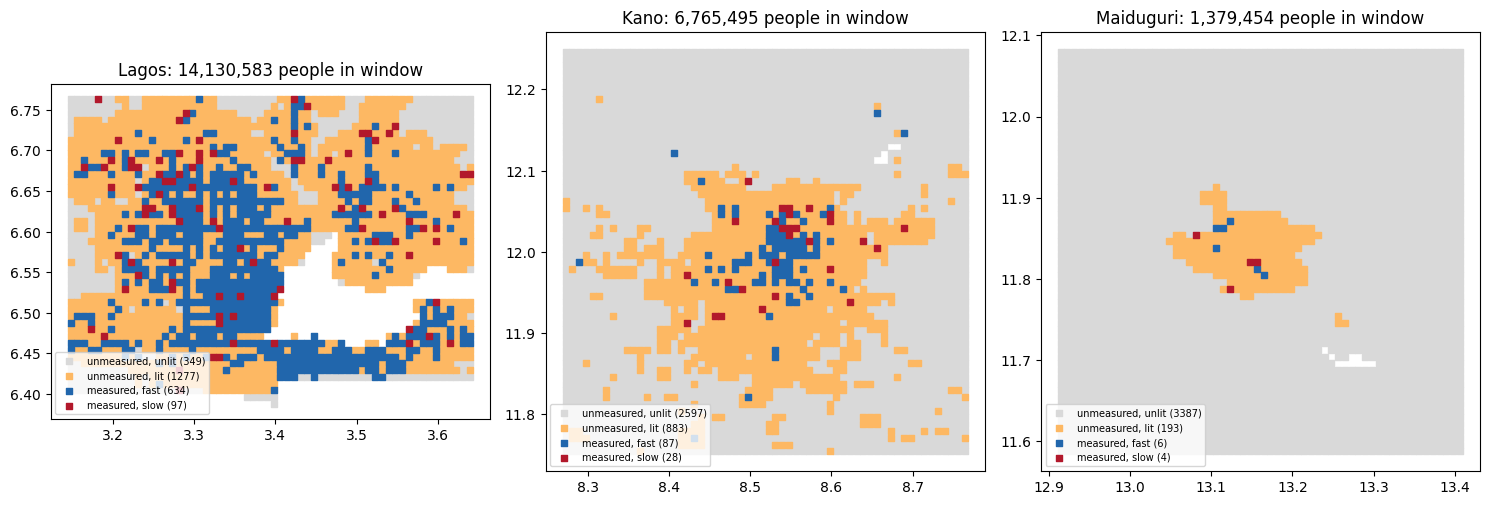

In [ ]:
import os, numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt

k = gpd.read_parquet(f"{D}/cells_pop_lga_ntl_travel_ookla.parquet")
k["lit"] = k.ntl_max > 0.33
k["measured"] = k.tests.fillna(0) >= 3

def status(g):
    return np.select([~g.measured & ~g.lit, ~g.measured & g.lit, g.measured & (g.dl_mbps >= 10)],
                     ["unmeasured, unlit", "unmeasured, lit", "measured, fast"], "measured, slow")

# exact six-state people (millions)
v6 = k[k.ntl_max.notna() & k.lga_id.notna()]
print((v6.groupby([status(v6), v6.lit])["pop"].sum() / 1e6).round(2), "\n")

# by-state table (G2 check 4)
st = k[k.lga_id.notna()].groupby("state").apply(lambda g: pd.Series({
    "people_M": g["pop"].sum() / 1e6,
    "lit": g.loc[g.lit, "pop"].sum() / g["pop"].sum(),
    "measured": g.loc[g.measured, "pop"].sum() / g["pop"].sum(),
    "any_tile": g.loc[g.tests.notna(), "pop"].sum() / g["pop"].sum()}), include_groups=False)
os.makedirs(f"{os.path.dirname(D)}/outputs", exist_ok=True)
st.to_csv(f"{os.path.dirname(D)}/outputs/state_table.csv")
print(st.sort_values("measured").round(3).to_string())

# three-city visual check (G2 check 6)
cities = {"Lagos": (3.39, 6.52), "Kano": (8.52, 12.00), "Maiduguri": (13.16, 11.83)}
COL = {"unmeasured, unlit": "#d9d9d9", "unmeasured, lit": "#fdb863",
       "measured, fast": "#2166ac", "measured, slow": "#b2182b"}
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, (x, y)) in zip(axs, cities.items()):
    w = k[(abs(k.geometry.x - x) < .25) & (abs(k.geometry.y - y) < .25)].copy()
    w["s"] = status(w)
    for s, c in COL.items():
        m = w.s == s
        ax.scatter(w.geometry.x[m], w.geometry.y[m], s=14, marker="s", color=c, label=f"{s} ({m.sum()})")
    ax.set_title(f"{name}: {w['pop'].sum():,.0f} people in window")
    ax.set_aspect("equal"); ax.legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.savefig(f"{os.path.dirname(D)}/outputs/G2_city_check.png", dpi=150)
plt.show()

In [ ]:
import os, numpy as np, pandas as pd, geopandas as gpd

MIN_TESTS, SPEED_T, LIT_RAD, SHARE_T, MIN_CELLS = 3, 10, 0.33, 0.5, 3

k = gpd.read_parquet(f"{D}/cells_pop_lga_ntl_travel_ookla.parquet")
c = pd.DataFrame(k.drop(columns="geometry"))
c = c[c.lga_id.notna()].copy()
c["valid"]    = c.ntl_max.notna()
c["lit"]      = c.valid & (c.ntl_max > LIT_RAD)
c["measured"] = c.tests.fillna(0) >= MIN_TESTS
c["fast"]     = c.measured & (c.dl_mbps >= SPEED_T)
c["slow"]     = c.measured & (c.dl_mbps < SPEED_T)

masks = {"valid": c.valid, "lit": c.lit, "measured": c.measured, "fast": c.fast, "slow": c.slow,
         "unm_lit": ~c.measured & c.lit, "unm_dark": ~c.measured & c.valid & ~c.lit,
         "slow_unlit": c.slow & c.valid & ~c.lit}
for n, m in masks.items():
    c["p_" + n] = c["pop"].where(m, 0)

T = c.groupby("lga_id").agg(
    state=("state", "first"), lga_name=("lga_name", "first"), pop=("pop", "sum"),
    meas_cells=("measured", "sum"), p_valid=("p_valid", "sum"), p_lit=("p_lit", "sum"),
    p_measured=("p_measured", "sum"), p_fast=("p_fast", "sum"), p_slow=("p_slow", "sum"),
    p_unm_lit=("p_unm_lit", "sum"), p_unm_dark=("p_unm_dark", "sum"),
    p_slow_unlit=("p_slow_unlit", "sum"))

def wmedian(x, w):
    o = np.argsort(x); x, w = x[o], w[o]; cw = np.cumsum(w)
    return x[np.searchsorted(cw, cw[-1] / 2)]
T["med_speed"] = (c[c.measured].groupby("lga_id")
                  .apply(lambda g: wmedian(g.dl_mbps.values, g["pop"].values), include_groups=False))
T["share_lit"] = T.p_lit / T.p_valid
T["share_measured"] = T.p_measured / T["pop"]

def classify(T, share_t=SHARE_T, min_cells=MIN_CELLS, speed_t=SPEED_T):
    ok, conn, pwr = T.meas_cells >= min_cells, T.med_speed >= speed_t, T.share_lit >= share_t
    return np.select([ok & conn & pwr, ok & conn & ~pwr, ok & ~conn & pwr, ok & ~conn & ~pwr, ~ok & pwr],
                     ["Connected, powered", "Connected, grid-weak", "Powered, slow", "Double-deprived",
                      "Unmeasured, lit"], "Unmeasured, dark")
T["cls"] = classify(T)

assert len(T) == 774 and abs(T["pop"].sum() - c["pop"].sum()) < 1
print("LGAs with a speed median:", int(T.med_speed.notna().sum()), "| NaN share_lit:", int(T.share_lit.isna().sum()))
print(T.share_lit.describe(percentiles=[.1, .25, .5, .75, .9]).round(3), "\n")
print(T.groupby("cls").agg(LGAs=("cls", "size"), people_M=("pop", lambda s: s.sum() / 1e6)).round(1), "\n")

rows = []
for mc in (1, 3, 5):
    for sh in (0.3, 0.5, 0.7):
        cl = pd.Series(classify(T, sh, mc)).value_counts()
        rows.append(pd.concat([pd.Series({"min_cells": mc, "share_t": sh}), cl]))
print(pd.DataFrame(rows).fillna(0).round(1).to_string(index=False), "\n")
print(T[T.cls == "Double-deprived"].sort_values("pop", ascending=False).head(10)
        [["state", "lga_name", "pop", "med_speed", "share_lit", "meas_cells", "share_measured"]].round(2))

T.to_parquet(f"{D}/lga_table_v0.parquet")
T.to_csv(f"{os.path.dirname(D)}/outputs/lga_table_v0.csv")

LGAs with a speed median: 327 | NaN share_lit: 0
count    774.000
mean       0.222
std        0.282
min        0.000
10%        0.000
25%        0.007
50%        0.094
75%        0.340
90%        0.704
max        1.000
Name: share_lit, dtype: float64 

                      LGAs  people_M
cls                                 
Connected, grid-weak    66      19.5
Connected, powered      96      46.7
Double-deprived         17       4.7
Powered, slow           14       4.3
Unmeasured, dark       560     135.5
Unmeasured, lit         21       5.9 

 min_cells  share_t  Unmeasured, dark  Connected, powered  Connected, grid-weak  Double-deprived  Unmeasured, lit  Powered, slow
       1.0      0.3             412.0               144.0                  97.0             56.0             35.0           30.0
       1.0      0.5             435.0               102.0                 139.0             69.0             12.0           17.0
       1.0      0.7             445.0                69.0     

In [ ]:
import glob, numpy as np, pandas as pd, geopandas as gpd

T = pd.read_parquet(f"{D}/lga_table_v0.parquet")
k = gpd.read_parquet(f"{D}/cells_pop_lga_ntl_travel_ookla.parquet")
c = pd.DataFrame(k.drop(columns="geometry")); c = c[c.lga_id.notna()]

# 1) where do the 15 biggest LGAs land?
print(T.sort_values("pop", ascending=False).head(15)
        [["state", "lga_name", "pop", "cls", "med_speed", "share_lit", "share_measured"]].round(2).to_string(), "\n")

# 2) travel time by class (people-weighted median, minutes): independent corroboration
c2 = c[c.travel.notna()].merge(T[["cls"]], left_on="lga_id", right_index=True)
def wmed(g):
    o = np.argsort(g.travel.values); cw = np.cumsum(g["pop"].values[o])
    return g.travel.values[o][np.searchsorted(cw, cw[-1] / 2)]
print(c2.groupby("cls").apply(wmed, include_groups=False).rename("median_travel_min").to_string(), "\n")

# 3) how dark is each state?
d = T.groupby("state").agg(LGAs=("cls", "size"), dark=("cls", lambda s: (s == "Unmeasured, dark").sum()))
d["share_dark"] = d.dark / d.LGAs
print(d.sort_values("share_dark").round(2).to_string(), "\n")

# 4) open the HV lines (metadata only, no heavy compute)
hv_path = glob.glob(f"{LAYERS}/all_transmission_line*/**/*.shp", recursive=True)
print(hv_path)
if hv_path:
    hv = gpd.read_file(hv_path[0])
    print(len(hv), hv.crs, hv.geom_type.value_counts().to_dict(), hv.total_bounds)
    print(list(hv.columns))
    for col in hv.columns:
        if col != "geometry" and hv[col].nunique() <= 12:
            print(col, hv[col].value_counts(dropna=False).to_dict())
else:
    import os; print(os.listdir(LAYERS))

                                 state          lga_name         pop                 cls  med_speed  share_lit  share_measured
lga_id                                                                                                                        
NGA.15.2_1   Federal Capital Territory          AbujaMun  2675475.92  Connected, powered      51.88       0.90            0.40
NGA.25.3_1                       Lagos          Alimosho  1960090.32  Connected, powered      22.67       0.96            0.64
NGA.25.2_1                       Lagos  Ajeromi/Ifelodun   991110.16  Connected, powered      52.20       1.00            0.67
NGA.25.13_1                      Lagos            Kosofe   983845.06  Connected, powered      56.43       1.00            0.67
NGA.25.16_1                      Lagos            Mushin   968015.97  Connected, powered     102.55       1.00            0.86
NGA.25.18_1                      Lagos      Oshodi/Isolo   958455.13  Connected, powered      33.26       1.00 

In [ ]:
import numpy as np, pandas as pd, geopandas as gpd

H = f"{LAYERS}/all_transmission_line (1)"
a = gpd.read_file(f"{H}/all_transmission_line.shp")
b = gpd.read_file(f"{H}/all_transmission_line_default.shp")
for n, g in [("main", a), ("default", b)]:
    print(n, len(g), list(g.columns), g.total_bounds.round(2), round(g.to_crs(32632).length.sum() / 1000), "km")

tg = a["tags"].fillna("") if "tags" in a.columns else pd.Series("", index=a.index)
print(tg[tg != ""].head(8).to_string())
for w in ["voltage", "construction", "proposed", "planned", "disused", "abandoned"]:
    print(w, int(tg.str.contains(w, case=False).sum()))
bad = tg.str.contains("construction|proposed|planned|disused|abandoned", case=False)
print("lines dropped as not existing:", int(bad.sum()), "| kept:", int((~bad).sum()))
hv = a[~bad].to_crs(32632)

k = gpd.read_parquet(f"{D}/cells_pop_lga_ntl_travel_ookla.parquet")
cp = k[["geometry"]].to_crs(32632)
d = gpd.sjoin_nearest(cp, hv[["geometry"]], how="left", distance_col="d_m")
d = d[~d.index.duplicated()]
k["hv_km"] = d["d_m"].reindex(k.index) / 1000
k.to_parquet(f"{D}/cells_pop_lga_ntl_travel_ookla_hv.parquet")

T = pd.read_parquet(f"{D}/lga_table_v0.parquet")
c = pd.DataFrame(k.drop(columns="geometry")); c = c[c.lga_id.notna()]
print("\nNaN hv_km:", int(c.hv_km.isna().sum()))
print(c.hv_km.describe(percentiles=[.05, .25, .5, .75, .95]).round(1))
for x in (5, 10, 25, 50):
    print(f"people within {x} km of a line:", round(c.loc[c.hv_km <= x, "pop"].sum() / c["pop"].sum(), 3))

def wmed(g, col):
    g = g[g[col].notna()]; o = np.argsort(g[col].values); cw = np.cumsum(g["pop"].values[o])
    return g[col].values[o][np.searchsorted(cw, cw[-1] / 2)]
c2 = c.merge(T[["cls"]], left_on="lga_id", right_index=True)
print("\nmedian km to HV line, people-weighted, by class:")
print(c2.groupby("cls").apply(wmed, col="hv_km", include_groups=False).round(1).to_string())

main 803 ['osm_id', 'power_line', 'tags', 'offset', 'geometry'] [ 294861.51  508119.63 1462709.72 1518002.81] 19651 km
default 803 ['osm_id', 'power_line', 'tags', 'offset', 'geometry'] [ 2.65  4.56 13.14 13.51] 19651 km
0    {"cables":"6","voltage":"132000","frequency":"...
1                                 {"voltage":"330000"}
2                                                   {}
3                    {"cables":"3","voltage":"330000"}
4                                 {"voltage":"330000"}
5                                 {"voltage":"330000"}
6    {"cables":"6","voltage":"330000","frequency":"...
7    {"cables":"6","voltage":"330000","frequency":"...
voltage 656
construction 0
proposed 0
planned 0
disused 0
abandoned 0
lines dropped as not existing: 0 | kept: 803

NaN hv_km: 0
count    1074053.0
mean          46.9
std           43.0
min            0.0
5%             2.6
25%           14.7
50%           34.7
75%           65.5
95%          136.4
max          272.6
Name: hv_km, dtype: 

In [ ]:
import os, glob, numpy as np, pandas as pd, geopandas as gpd

RES = 0.008333333299798792
OUT = f"{os.path.dirname(D)}/outputs"
k = gpd.read_parquet(f"{D}/cells_pop_lga_ntl_travel_ookla_hv.parquet")
x0 = (k.geometry.x - (k.col + 0.5) * RES).median()
y0 = (k.geometry.y + (k.row + 0.5) * RES).median()

# 1) the three point layers
FAC = {"health": "health-care-facilities-primary-secondary-and-tertiary.geojson",
       "secondary school": "secondary-schools.geojson",
       "tertiary school": "tertiary-schools.geojson"}
parts = []
for kind, fn in FAC.items():
    g = gpd.read_file(f"{LAYERS}/{fn}")
    print(kind, len(g), g.crs, g.geom_type.value_counts().to_dict(), list(g.columns)[:10])
    g = g[g.geometry.notna() & ~g.geometry.is_empty].copy()
    g["kind"] = kind
    g["sub"] = g["type"] if (kind == "health" and "type" in g.columns) else kind
    parts.append(g[["kind", "sub", "geometry"]])
fac = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), geometry="geometry", crs="EPSG:4326")
if (fac.geom_type != "Point").any():
    fac["geometry"] = fac.geometry.centroid

# 2) facility -> its 1 km cell -> measured / lit status
fac["col"] = np.floor((fac.geometry.x - x0) / RES).astype(int)
fac["row"] = np.floor((y0 - fac.geometry.y) / RES).astype(int)
cell = pd.DataFrame(k[["row", "col", "tests", "dl_mbps", "ntl_max", "hv_km", "travel"]])
f = fac.merge(cell, on=["row", "col"], how="left", indicator="m")
f["in_grid"] = f["m"] == "both"
f = f.drop(columns="m")
f["measured"] = f.tests.fillna(0) >= 3
f["status"] = np.select([~f.in_grid, ~f.measured, f.dl_mbps >= 10],
                        ["cell not in population grid", "unmeasured", "measured fast"], "measured slow")
f["light"] = np.select([~f.in_grid | f.ntl_max.isna(), f.ntl_max > 0.33], ["n/a", "lit"], "unlit")
f["exposed"] = (f.light == "unlit") & f.status.isin(["unmeasured", "measured slow"])

# 3) LGA by polygon, nearest within 2 km as fallback (same rule as the cells)
shp = glob.glob(f"{LAYERS}/gadm40_NGA_shp/**/gadm40_NGA_2.shp", recursive=True)[0]
lga = gpd.read_file(shp)
lga = lga[lga["TYPE_2"] != "Water body"][["ID_2", "geometry"]].rename(columns={"ID_2": "lga_id"})
f = f.sjoin(lga, how="left", predicate="within").drop(columns="index_right")
f = f[~f.index.duplicated()]
miss = f.lga_id.isna()
if miss.any():
    r = gpd.sjoin_nearest(f.loc[miss].drop(columns="lga_id").to_crs(32632), lga.to_crs(32632),
                          how="left", max_distance=2000).drop(columns="index_right")
    r = r[~r.index.duplicated()]
    f.loc[r.index, "lga_id"] = r["lga_id"]

# 4) sensitivity: a measured cell within ~1 km
mc = k.loc[k.tests.fillna(0) >= 3, ["geometry"]].to_crs(32632)
nb = gpd.sjoin_nearest(f[["geometry"]].to_crs(32632), mc, how="left", max_distance=1000)
nb = nb[~nb.index.duplicated()]
f["meas_1km"] = nb["index_right"].reindex(f.index).notna()
f["exposed_near_meas"] = f.exposed & f.meas_1km

print("\nfacilities:", len(f), "| not in population grid:", int((~f.in_grid).sum()),
      "| no LGA:", int(f.lga_id.isna().sum()))
print(f.pivot_table(index=["kind", "status"], columns="light", values="row", aggfunc="size", fill_value=0), "\n")
ex = f.groupby("kind").agg(n=("row", "size"), exposed=("exposed", "sum"),
                           exposed_but_measured_cell_within_1km=("exposed_near_meas", "sum"))
ex["exposed_share"] = ex.exposed / ex.n
print(ex.round(3), "\n")

# 5) LGA table v1: facility counts + HV and travel medians (corroboration only)
T = pd.read_parquet(f"{D}/lga_table_v0.parquet"); T.index = T.index.astype(str)
f["cls"] = f.lga_id.map(T["cls"])
byc = f.groupby("cls").agg(facilities=("row", "size"), exposed=("exposed", "sum"))
byc["exposed_share"] = byc.exposed / byc.facilities
print(byc.round(3), "\n")

cnt = f.groupby("lga_id").agg(n_health=("kind", lambda s: int((s == "health").sum())),
                              n_schools=("kind", lambda s: int((s != "health").sum())),
                              n_exposed=("exposed", "sum"))
cnt.index = cnt.index.astype(str)
T = T.join(cnt).fillna({"n_health": 0, "n_schools": 0, "n_exposed": 0})

c = pd.DataFrame(k.drop(columns="geometry")); c = c[c.lga_id.notna()].copy()
c["lga_id"] = c["lga_id"].astype(str)
def wm(g, col):
    g = g[g[col].notna()]
    if len(g) == 0: return np.nan
    o = np.argsort(g[col].values); cw = np.cumsum(g["pop"].values[o])
    return g[col].values[o][np.searchsorted(cw, cw[-1] / 2)]
T["med_hv_km"] = c.groupby("lga_id").apply(wm, col="hv_km", include_groups=False)
T["med_travel"] = c.groupby("lga_id").apply(wm, col="travel", include_groups=False)

print(T.sort_values("n_exposed", ascending=False).head(10)
        [["state", "lga_name", "cls", "pop", "n_health", "n_schools", "n_exposed"]].round(0).to_string(), "\n")
print("totals | health:", int(T.n_health.sum()), "| schools:", int(T.n_schools.sum()),
      "| exposed:", int(T.n_exposed.sum()))

T.to_parquet(f"{D}/lga_table_v1.parquet"); T.to_csv(f"{OUT}/lga_table_v1.csv")
f.to_parquet(f"{D}/facilities_status.parquet")
pd.DataFrame(f.drop(columns="geometry")).to_csv(f"{OUT}/facility_status.csv", index=False)

health 49329 EPSG:4326 {'Point': 49329} ['id', 'latitude', 'longitude', 'contact_phone', 'contact_name', 'ri_service_status', 'cce_quantity', 'cce_available', 'cce_lastupdated', 'category']
secondary school 23501 EPSG:4326 {'Point': 23501} ['id', 'state_code', 'source', 'name', 'ward_code', 'category', 'subtype', 'management', 'education', 'poi_type']
tertiary school 950 EPSG:4326 {'Point': 950} ['id', 'state_code', 'source', 'name', 'ward_code', 'category', 'subtype', 'management', 'education', 'poi_type']

facilities: 73780 | not in population grid: 33 | no LGA: 18
light                                           lit  n/a  unlit
kind             status                                        
health           cell not in population grid      0   29      0
                 measured fast                 3475    5    165
                 measured slow                  759    0     80
                 unmeasured                   12057   23  32736
secondary school cell not in population gr

In [ ]:
import os, requests, pandas as pd, geopandas as gpd

# A) facility provenance and status fields
fh = gpd.read_file(f"{LAYERS}/health-care-facilities-primary-secondary-and-tertiary.geojson")
print(list(fh.columns))
for col in ["type", "functional_status", "category", "ri_service_status"]:
    if col in fh.columns:
        print(col, fh[col].value_counts(dropna=False).head(8).to_dict())
for fn in ["secondary-schools.geojson", "tertiary-schools.geojson"]:
    s = gpd.read_file(f"{LAYERS}/{fn}")
    for col in ["source", "management", "poi_type"]:
        if col in s.columns:
            print(fn, col, s[col].value_counts(dropna=False).head(6).to_dict())

# B) Meta Relative Wealth Index on HDX
API = "https://data.humdata.org/api/3/action/package_search"
res = requests.get(API, params={"q": "relative wealth index", "rows": 10}, timeout=60).json()["result"]["results"]
for p in res:
    print("\n", p["name"], "|", p.get("license_title"), "|", p.get("dataset_date"), "|", len(p["resources"]), "resources")

pkg = next((p for p in res if "relative" in p["name"] and "wealth" in p["name"]), None)
print("\nchosen:", pkg["name"] if pkg else None)
if pkg:
    print("license:", pkg.get("license_title"), "|", pkg.get("license_id"),
          "| org:", (pkg.get("organization") or {}).get("title"))
    print("notes:", (pkg.get("notes") or "")[:300])
    cand = [r for r in pkg["resources"] if any(t in (r["name"] + r["url"]).lower() for t in ("nga", "nigeria"))]
    for r in cand:
        print(r["name"], "|", r["format"], "|", r["url"], "|", r.get("size"))
    if cand:
        out = f"{os.path.dirname(D)}/raw/rwi_nga.csv"
        with requests.get(cand[0]["url"], stream=True, timeout=120) as rr:
            rr.raise_for_status()
            with open(out, "wb") as fh_:
                for ch in rr.iter_content(1 << 20):
                    fh_.write(ch)
        rwi = pd.read_csv(out)
        print(rwi.shape, list(rwi.columns))
        print(rwi.describe().round(3))

['id', 'latitude', 'longitude', 'contact_phone', 'contact_name', 'ri_service_status', 'cce_quantity', 'cce_available', 'cce_lastupdated', 'category', 'global_id', 'name', 'alternate_name', 'functional_status', 'type', 'ownership', 'ward_code', 'accessibility', 'source', 'ward_name', 'lga_code', 'lga_name', 'state_code', 'state_name', 'geometry']
type {'Primary': 46984, 'Secondary': 1437, 'Tertiary': 908}
functional_status {'Functional': 35654, 'Unknown': 13485, 'Non Functional': 100, 'Non Functional/Dilapidated/Abandoned': 52, 'Non Functional/Under Construction/Renovation': 16, 'Non Functional/Newly Commissioned': 15, 'Partially Functional': 7}
category {'Primary Health Center': 28880, 'Dispensary': 8628, 'Maternity Home': 4424, 'Private Non Profit': 1207, 'Primary Health Clinic': 1156, 'Medical Center': 956, 'Specialist Hospital': 701, 'General Hospital': 694}
ri_service_status {nan: 30621, 1.0: 11708, 0.0: 7000}
secondary-schools.geojson source {'NMIS': 16719, 'GRID': 3388, 'OSGOF': 

In [ ]:
import os, re, glob, requests, numpy as np, pandas as pd, geopandas as gpd
from scipy.stats import spearmanr

RAW = f"{os.path.dirname(D)}/raw"

# A) licence text as HDX records it
res = requests.get("https://data.humdata.org/api/3/action/package_search",
                   params={"q": "relative wealth index", "rows": 10}, timeout=60).json()["result"]["results"]
pkg = next(p for p in res if p["name"] == "relative-wealth-index")
for key in ["license_title", "license_other", "dataset_source", "methodology", "methodology_other", "caveats"]:
    print(key, "->", pkg.get(key))
print("notes:", (pkg.get("notes") or "")[:1500])

# B) health layer: provenance, functional status vs exposure, state cross-check
fh = gpd.read_file(f"{LAYERS}/health-care-facilities-primary-secondary-and-tertiary.geojson")
print("\nhealth source:", fh["source"].value_counts(dropna=False).head(8).to_dict())

f = gpd.read_parquet(f"{D}/facilities_status.parquet")
h = f[f.index < len(fh)].copy()
fhi = fh.reset_index(drop=True)
assert (h.kind == "health").all()
assert np.allclose(h.geometry.x.values, fhi.geometry.x.reindex(h.index).values)   # row alignment check
h["fs"] = fhi.loc[h.index, "functional_status"].values
h["fs3"] = np.where(h["fs"] == "Functional", "Functional",
                    np.where(h["fs"] == "Unknown", "Unknown", "Non/partly functional"))
g3 = h.groupby("fs3").agg(n=("row", "size"), exposed=("exposed", "sum"))
g3["exposed_share"] = g3.exposed / g3.n
print(g3.round(3), "\n")

norm = lambda s: re.sub(r"[^a-z]", "", str(s).lower())
T = pd.read_parquet(f"{D}/lga_table_v1.parquet"); T.index = T.index.astype(str)
mine = h.lga_id.astype(str).map(T["state"]).map(norm)
theirs = fhi.loc[h.index, "state_name"].map(norm)
ok = mine == theirs
print("state agrees with the file's own state_name:", round(float(ok.mean()), 4))
print(pd.Series(list(zip(theirs[~ok], mine[~ok]))).value_counts().head(6))

# C) RWI -> cells -> LGAs
rwi = pd.read_csv(f"{RAW}/rwi_nga.csv")
rg = gpd.GeoDataFrame(rwi, geometry=gpd.points_from_xy(rwi.longitude, rwi.latitude), crs=4326)
print("\nRWI points:", len(rg), "| mean error / std of rwi:", round(rwi.error.mean() / rwi.rwi.std(), 2))

k = gpd.read_parquet(f"{D}/cells_pop_lga_ntl_travel_ookla_hv.parquet")
cp = k[["geometry"]].to_crs(32632)
d2 = gpd.sjoin_nearest(cp, rg.to_crs(32632)[["rwi", "error", "geometry"]], how="left",
                       max_distance=2000, distance_col="d_rwi")
d2 = d2[~d2.index.duplicated()]
k["rwi"] = d2["rwi"].reindex(k.index)
k["d_rwi"] = d2["d_rwi"].reindex(k.index)
k.to_parquet(f"{D}/cells_pop_lga_ntl_travel_ookla_hv_rwi.parquet")

c = pd.DataFrame(k.drop(columns="geometry")); c = c[c.lga_id.notna()].copy()
c["lga_id"] = c["lga_id"].astype(str)
m = c.rwi.notna()
print("cells with RWI:", round(float(m.mean()), 4),
      "| people with RWI:", round(float(c.loc[m, "pop"].sum() / c["pop"].sum()), 4))
print(c.d_rwi.describe().round(0))

w = c[m].assign(wr=c.loc[m, "rwi"] * c.loc[m, "pop"]).groupby("lga_id").agg(wr=("wr", "sum"), wp=("pop", "sum"))
T["rwi_pw"] = (w.wr / w.wp).reindex(T.index)

shp = glob.glob(f"{LAYERS}/gadm40_NGA_shp/**/gadm40_NGA_2.shp", recursive=True)[0]
lga = gpd.read_file(shp)
lga = lga[lga["TYPE_2"] != "Water body"][["ID_2", "geometry"]].rename(columns={"ID_2": "lga_id"})
pts = rg.sjoin(lga, predicate="within")
T["rwi_pts"] = pts.groupby("lga_id")["rwi"].mean().reindex(T.index)
print("\nLGAs with no RWI cell match:", int(T.rwi_pw.isna().sum()),
      "| no RWI point inside polygon:", int(T.rwi_pts.isna().sum()),
      "| rank corr of the two:", round(float(spearmanr(T.rwi_pw, T.rwi_pts, nan_policy="omit").correlation), 3))

cut = T.rwi_pw.quantile(1 / 3)
T["poor"] = T.rwi_pw <= cut
print("\nbottom-third cut-off RWI:", round(float(cut), 3))
print(T.groupby("cls").agg(LGAs=("cls", "size"), people_M=("pop", lambda s: s.sum() / 1e6),
                           median_rwi=("rwi_pw", "median"), share_poor=("poor", "mean")).round(2).to_string(), "\n")
T["assessable"] = T.meas_cells >= 3
print(T.groupby("assessable")["rwi_pw"].describe().round(2))
for col in ["share_measured", "share_lit"]:
    print("rank corr RWI vs", col, round(float(spearmanr(T.rwi_pw, T[col], nan_policy="omit").correlation), 3))

T.to_parquet(f"{D}/lga_table_v2.parquet"); T.to_csv(f"{os.path.dirname(D)}/outputs/lga_table_v2.csv")

license_title -> Other
license_other -> Creative Commons Attribution-Non Commercial 4.0 International (CC BY-NC 4.0)

Attribution — You must give appropriate credit, provide a link to the license, and indicate if changes were made. You may do so in any reasonable manner, but not in any way that suggests the licensor endorses you or your use.

NonCommercial — You may not use the material for commercial purposes.

Please cite / attribute any use of this dataset using the following: 
Microestimates of wealth for all low- and middle-income countries
Guanghua Chi, Han Fang, Sourav Chatterjee, Joshua E. Blumenstock
Proceedings of the National Academy of Sciences Jan 2022, 119 (3) e2113658119; DOI: 10.1073/pnas.2113658119
dataset_source -> Facebook
methodology -> Other
methodology_other -> Researchers at the University of California - Berkeley and Facebook developed micro-estimates of wealth and poverty that cover the populated surface of all 135 low and middle-income countries (LMICs) at 2.4

In [ ]:
import os, shutil, time
import pandas as pd

ROOT = os.path.dirname(D)                      # /content/drive/MyDrive/digital-divide
for sub in ["raw", "interim", "outputs", "docs", "runtime_copies"]:
    os.makedirs(f"{ROOT}/{sub}", exist_ok=True)

# 1) the one in-memory table not yet on Drive: health facilities with functional status
try:
    hh = pd.DataFrame(h.drop(columns="geometry"))[["kind", "row", "col", "lga_id", "status", "light", "exposed", "fs3"]]
    hh["facility_id"] = fhi.loc[h.index, "id"].values
    hh.to_parquet(f"{D}/health_functional_status.parquet")
    print("saved health_functional_status:", len(hh), "rows")
except (NameError, KeyError) as e:
    print("health table not in memory, skipped:", e)

# 2) stray runtime-local files (excluding Drive, the extracted archive, and big files)
SKIP = ("/content/drive", "/content/onsset", "/content/sample_data", "/content/.config")
copied = 0
for dp, dn, fn in os.walk("/content"):
    if dp.startswith(SKIP):
        dn[:] = []
        continue
    for n in fn:
        p = os.path.join(dp, n)
        if n.startswith(".") or n.endswith(".rar") or os.path.getsize(p) > 200e6:
            continue
        dst = f"{ROOT}/runtime_copies/{n}"
        if not os.path.exists(dst) or os.path.getsize(dst) != os.path.getsize(p):
            shutil.copy2(p, dst); copied += 1; print("  copied", p)
print("runtime-only files copied:", copied)

# 3) decision log and source register (these exist only in chat otherwise)
METHODS = """# METHODS log: decisions and deviations from the build guide (written 2026-10-19)

## Data handling
- LGAs: GADM 4.0 level 2. Lake Chad (TYPE_2 = Water body) removed -> 774 LGAs. Join key is lga_id (GADM string ID_2, e.g. NGA.34.4_1); never join on name (10 names repeat across states).
- Population: nga_ppp_2020.tif (WorldPop 2020 per the package docx; not verified at source). Aggregated 10x10 by SUM to 0.00833 deg (~0.92 km) cells; bottom/right padded with zeros; nodata and negatives set to 0. Total 216,682,712 (float64; the earlier 216,682,016 was a float32 summing difference). 1,079,819 populated cells.
- Cell -> LGA: cell centre within polygon. 10,907 cells (0.38% of people) fell outside every polygon; 5,141 of them (652,612 people) were assigned to the nearest LGA within 2 km (EPSG:32632) and flagged rescued; 5,766 cells (171,724 people, 0.079%) stay unassigned and are excluded from LGA aggregates. Lake Chad shore cells attach to adjacent Borno LGAs.
- Night lights: raster max is 1,250.2 (an earlier note said 807.7: wrong). 4,310,610 valid pixels, 3.1% non-zero. Sampled at 4 sub-points per cell (+/- 1/4 cell); ntl_max = brightest; 0.49% of cells NaN. LIT_RAD = 0.33 is provisional (product and year unconfirmed); 30.0% of people are in lit cells at that cut.
- Travel time: sampled at the cell centre; units assumed minutes (unverified); corroboration only.
- HV lines: 803 segments, 19,651 km; the two shapefiles are identical. 656 carry a voltage tag; none has construction/proposed/planned wording, so all are treated as existing (not proven). Distance to nearest line in EPSG:32632. Corroboration only; not in any class rule.
- Ookla: Nigeria Ookla.gpkg has no CRS stored; EPSG:4326 assigned. 9,234 tiles, 42,838 tests; no quarter or mobile/fixed field. Each tile goes to the cell containing its centre; tests summed; speed tests-weighted. 6,685 cells, 6,678 in the populated grid; 18 tests fall in unpopulated cells. At MIN_TESTS=3, 8.2% of people are in measured cells.
- Primary schools: no coordinates -> excluded. Facilities used: health, secondary schools, tertiary schools (73,780 points). Not labelled GRID3 (compilations; see DATA_SOURCES_draft.md).
- Facility status is read from the 1 km cell containing the facility. 'Exposed' = unlit AND (unmeasured or measured slow). 99.8% of exposed facilities are exposed through 'unmeasured', so the statement is about visibility and lights, not measured slowness.
- RWI: 103,424 points at 2.4 km; mean per-point error ~ std of the values, so used only as an LGA mean and in terciles. LGA need = people-weighted mean over 1 km cells (nearest RWI point within 2 km); 94.3% of people have a value; guide's point mean is a cross-check (rank corr 0.916). Poor = bottom third of LGAs (cut-off RWI -0.217).
- Speed is reported as medians only.

## Thresholds (fixed before looking at outcomes)
MIN_TESTS=3 (sens. 1, 5); SPEED_T=10 Mbps (5, 25); SHARE_T=0.5 (0.3, 0.7); LIT_RAD=0.33 (0.1, 1.0); MIN_CELLS=3 (1, 5).

## Deviations from the guide
1. Evidence rule: the guide's 'Low evidence = >=50% of people unmeasured' would class 757 of 774 LGAs as low evidence (only 17 pass). Replaced by 'assessable if >=3 measured cells' (193 LGAs). The rest are classed by lights only: 'Unmeasured, lit' / 'Unmeasured, dark'.
2. Facility status from the facility's own 1 km cell (guide: nearest tile within 1 km); the within-1 km variant is a sensitivity flag (changes 703 of 46,376 exposed).
3. LGA need is people-weighted over cells (guide: mean of points inside the polygon).
4. HV distance computed (guide allowed skipping); corroboration only.
5. Ookla arrived as one GeoPackage (guide: Parquet); facility layers are compilations (guide: GRID3).

## Provisional readings (frozen only in Phase 8)
- Classes: Unmeasured dark 560 LGAs / 135.5M people; Connected powered 96 / 46.7M; Connected grid-weak 66 / 19.5M; Unmeasured lit 21 / 5.9M; Double-deprived 17 / 4.7M; Powered slow 14 / 4.3M. Double-deprived ranged 1-79 across the sensitivity grid, so it is reported as a shortlist.
- Median km to HV line: lit classes 3.4-6.3, dark classes 10.1-23.7 (corroborates the lights axis).
- Median RWI: assessable LGAs 0.57 vs 'unmeasured' LGAs -0.18. RWI is partly built from satellite and Facebook connectivity data, so its link to lights and measurement is association, not independent confirmation.

## Open items
- Night-lights product and year; Ookla quarter(s) and mobile/fixed; whether the two Ookla source layers carry identical values (only quadkeys and column names were compared).
- Licenses for population, night lights, GADM, facilities, HV lines [VERIFY].
- 30 Ookla tiles with no LGA match (first inspection) not yet looked at.
- Health points disagree with the file's own state label for ~3% of facilities after spelling differences (mostly border areas); GADM geometry is used.
- Facility 'Unknown' functional status is 27% of health facilities.
"""
SOURCES = """# DATA_SOURCES draft (accessed 2026-10-19)
| Layer | Provider / URL / DOI | Year | License | Used for |
|---|---|---|---|---|
| Mobile speed tiles | Ookla Open Data, provided folder (Nigeria Ookla.gpkg) | quarter unknown | CC BY-NC-SA 4.0 [VERIFY] | measured speed |
| Population | Zenodo 10.5281/zenodo.15265285 (OnSSET package); WorldPop 2020 per package docx | 2020 | [VERIFY] | people per 1 km cell |
| Night lights | same package; product and year unknown | ? | [VERIFY] | electricity-infrastructure proxy |
| Travel time | same package; units unverified | ? | [VERIFY] | corroboration |
| HV lines | same package; OSM-style attributes (osm_id, power_line, tags) | ? | [VERIFY] | corroboration |
| Health facilities | same package; compiled, `source` column: eHA Polio, GRID, SPHCMB, NPHCDA, OSGOF, Measles Campaign, KDBS, others | ? | [VERIFY] | exposure |
| Secondary / tertiary schools | same package; `source`: NMIS, GRID, OSGOF, Proxy Logistics, eHA Polio, Bauchi JSI MCSP | ? | [VERIFY] | exposure |
| LGA boundaries | GADM 4.0 level 2 (package) | 4.0 | GADM terms [VERIFY] | aggregation |
| Relative Wealth Index | Meta AI for Good via HDX 'relative-wealth-index', nga_relative_wealth_index.csv (103,424 points, 2.4 km) | HDX range 2021-04 to 2023-02; data year not stated | CC BY-NC 4.0 (HDX license_other) | need |

Cite RWI as: Chi, Fang, Chatterjee, Blumenstock (2022), Microestimates of wealth for all low- and middle-income countries, PNAS 119(3) e2113658119, DOI 10.1073/pnas.2113658119.
"""
for name, txt in [("METHODS_log.md", METHODS), ("DATA_SOURCES_draft.md", SOURCES)]:
    with open(f"{ROOT}/docs/{name}", "w", encoding="utf-8") as fh_:
        fh_.write(txt)
print("wrote docs/METHODS_log.md and docs/DATA_SOURCES_draft.md")

# 4) manifest + verification
rows = []
for dp, dn, fn in os.walk(ROOT):
    for n in fn:
        p = os.path.join(dp, n)
        rows.append((os.path.relpath(p, ROOT), round(os.path.getsize(p) / 1e6, 2),
                     time.strftime("%Y-%m-%d %H:%M", time.localtime(os.path.getmtime(p)))))
man = pd.DataFrame(rows, columns=["file", "MB", "modified (runtime clock)"]).sort_values("file")
man.to_csv(f"{ROOT}/docs/MANIFEST.csv", index=False)
lay = man[man.file.str.startswith("interim/layers")]
print(man[~man.file.str.startswith("interim/layers")].to_string(index=False))
print(f"interim/layers: {len(lay)} files, {lay.MB.sum():.0f} MB | total on Drive: {man.MB.sum() / 1000:.2f} GB")

must = ["raw/onsset_data.rar", "raw/Nigeria Ookla.gpkg", "raw/rwi_nga.csv", "interim/lga_774.gpkg",
        "interim/ookla_tiles.gpkg", "interim/cells_pop_lga_ntl_travel_ookla_hv_rwi.parquet",
        "interim/lga_table_v2.parquet", "interim/facilities_status.parquet", "interim/layers"]
print("\nmissing:", [m for m in must if not os.path.exists(f"{ROOT}/{m}")] or "none")
for fn, col, n in [("cells_pop_lga_ntl_travel_ookla_hv_rwi.parquet", "pop", 1079819),
                   ("lga_table_v2.parquet", "pop", 774), ("facilities_status.parquet", "kind", 73780)]:
    x = pd.read_parquet(f"{D}/{fn}", columns=[col])
    print(f"{fn}: {len(x):,} rows", "OK" if len(x) == n else f"EXPECTED {n:,}",
          "| pop sum" if col == "pop" else "", round(x[col].sum()) if col == "pop" else "")

os.sync()
# before closing the tab, optionally force Drive to commit:
# from google.colab import drive; drive.flush_and_unmount()

saved health_functional_status: 49329 rows
  copied /content/listing.txt
  copied /content/primary/nigerian-primary-schools.shx
  copied /content/primary/nigerian-primary-schools.dbf
  copied /content/primary/nigerian-primary-schools.prj
runtime-only files copied: 4
wrote docs/METHODS_log.md and docs/DATA_SOURCES_draft.md
                                                 file      MB modified (runtime clock)
                           docs/DATA_SOURCES_draft.md    0.00         2026-10-19 21:14
                                  docs/METHODS_log.md    0.00         2026-10-19 21:14
                        interim/cells_pop_1km.parquet   22.50         2026-10-19 20:33
                        interim/cells_pop_lga.parquet   27.44         2026-10-19 20:36
             interim/cells_pop_lga_ntl_travel.parquet   29.91         2026-10-19 20:45
       interim/cells_pop_lga_ntl_travel_ookla.parquet   25.36         2026-10-19 20:46
    interim/cells_pop_lga_ntl_travel_ookla_hv.parquet   34.33      

In [ ]:
import os, re, numpy as np, pandas as pd

if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")   # runtime may have reset overnight
ROOT = "/content/drive/MyDrive/digital-divide"
D, OUT = f"{ROOT}/interim", f"{ROOT}/outputs"
SHARE_T = 0.5

# 0) which HV files does the archive list? (provenance question from the Zenodo record)
lines = open(f"{ROOT}/runtime_copies/listing.txt", errors="ignore").read().splitlines()
print([l.strip() for l in lines if re.search(r"line|HV|transmission|voltage|planned", l, re.I)][:25], "\n")

# 1) tiers
T = pd.read_parquet(f"{D}/lga_table_v2.parquet")
gap = ~T.cls.isin(["Connected, powered", "Connected, grid-weak"])
T["tier"] = np.select([gap & T.poor, gap & ~T.poor], ["Tier 1", "Tier 2"], "Tier 3")
T["exposed_people"] = T.p_unm_dark + T.p_slow_unlit
T["fix"] = np.where(T.share_lit < SHARE_T, "power-led (co-deploy)", "telecom-led")
T["people_low"] = T.p_slow
T["people_high"] = T["pop"] - T.p_fast

tot_exp = T.exposed_people.sum()
g = T.groupby("tier").agg(LGAs=("tier", "size"), people_M=("pop", lambda s: s.sum() / 1e6),
                          exposed_M=("exposed_people", lambda s: s.sum() / 1e6),
                          facilities_exposed=("n_exposed", "sum"))
g["share_of_exposed"] = g.exposed_M * 1e6 / tot_exp
print(g.round(2).to_string(), "\n")
print("Tier 1 by class:\n", T[T.tier == "Tier 1"].cls.value_counts().to_string(), "\n")

t1 = T[T.tier == "Tier 1"].sort_values("exposed_people", ascending=False)
top = t1.head(20)
print("top-20 cover", round(top.exposed_people.sum() / t1.exposed_people.sum(), 3),
      "of Tier-1 exposed people | top-50:", round(t1.head(50).exposed_people.sum() / t1.exposed_people.sum(), 3))
print(top[["state", "lga_name", "pop", "exposed_people", "share_lit", "med_hv_km", "n_exposed", "rwi_pw", "fix"]]
        .round(2).to_string(), "\n")

st = t1.groupby("state").agg(LGAs=("tier", "size"), exposed_M=("exposed_people", lambda s: s.sum() / 1e6))
st["of_state_LGAs"] = T.groupby("state").size().reindex(st.index)
print(st.sort_values("exposed_M", ascending=False).head(10).round(2).to_string(), "\n")
print("fix type in Tier 1:", t1["fix"].value_counts().to_dict())

# 2) cross-check: 'poor' from the plain point mean (the guide's version)
t1b = gap & (T.rwi_pts <= T.rwi_pts.quantile(1 / 3))
a, b = set(t1.index), set(T.index[t1b])
print("\nTier 1 with point-mean RWI:", len(b), "| overlap (Jaccard):", round(len(a & b) / len(a | b), 3))

# 3) save, and log today's provenance findings
T.to_parquet(f"{D}/lga_table_v3.parquet"); T.to_csv(f"{OUT}/lga_table_v3.csv")
top.to_csv(f"{OUT}/priority_top20.csv")
add = """
## Update 2026-10-20
- Zenodo record 10.5281/zenodo.15265285 (v1, 2025-04-22, CC BY 4.0, components carry own terms; a newer version exists): health facilities and educational institutions are 'from GRID3'; boundaries GADM; night lights only 'Night time light for Nigeria - raster' (no product or year). Lights pixel size is 15 arc-seconds (~450 m), the VIIRS-DNB grid; product and year unconfirmed.
- HV lines: the record lists existing and planned lines from the Transmission Company of Nigeria as separate files. Our file has OSM-style fields, so its provenance and existing-only status are unconfirmed.
- Source study reports national electricity access ~62% (urban ~91%, rural ~30%); lights show 30% of people in lit cells, so 'dark' = no detectable light.
- Priority rule: Tier 1 = gap class (not Connected powered / grid-weak) AND poorest-third RWI; ranked by exposed people (unlit people in unmeasured or slow cells).
"""
with open(f"{ROOT}/docs/METHODS_log.md", "a", encoding="utf-8") as fh_:
    fh_.write(add)

Mounted at /content/drive
['2022-06-02 06:50:06 ....A            5            5  Data used in GIS-based rural electrification planning study on Nigeria using OnSSET/High-voltage lines (Existing)/all_transmission_line (1)/all_transmission_line.cst', '2022-06-02 06:50:06 ....A       431372         7581  Data used in GIS-based rural electrification planning study on Nigeria using OnSSET/High-voltage lines (Existing)/all_transmission_line (1)/all_transmission_line.dbf', '2022-06-02 06:50:06 ....A          749          379  Data used in GIS-based rural electrification planning study on Nigeria using OnSSET/High-voltage lines (Existing)/all_transmission_line (1)/all_transmission_line.prj', '2022-06-02 06:50:06 ....A       866972       420893  Data used in GIS-based rural electrification planning study on Nigeria using OnSSET/High-voltage lines (Existing)/all_transmission_line (1)/all_transmission_line.shp', '2022-06-02 06:50:06 ....A         6524         2431  Data used in GIS-based rural el

In [ ]:
import os, glob, numpy as np, pandas as pd

ROOT = "/content/drive/MyDrive/digital-divide"; D = f"{ROOT}/interim"; LAYERS = f"{D}/layers"

# 0) what service did the HV file come from?
for p in glob.glob(f"{LAYERS}/**/wfsrequest.txt", recursive=True):
    print(p, "\n", open(p, errors="ignore").read(), "\n")

# 1) zero-lit LGAs: raster blank, or just below the cut-off?
T = pd.read_parquet(f"{D}/lga_table_v3.parquet")
print(T.groupby("tier")["fix"].value_counts().to_string(), "\n")

c = pd.read_parquet(f"{D}/cells_pop_lga_ntl_travel_ookla_hv_rwi.parquet", columns=["lga_id", "pop", "ntl_max"])
c = c[c.lga_id.notna() & c.ntl_max.notna()].copy(); c["lga_id"] = c.lga_id.astype(str)
c["any"] = c.ntl_max > 0
g = c.groupby("lga_id").apply(lambda x: pd.Series({
        "cells": len(x), "cells_any_light": x["any"].mean(), "max_ntl": x.ntl_max.max(),
        "p95_ntl": x.ntl_max.quantile(.95)}), include_groups=False)
Z = T.join(g)
zero = Z[Z.share_lit < 0.005]
print("LGAs with <0.5% of people lit:", len(zero), "| people (M):", round(zero["pop"].sum() / 1e6, 1))
print("   no cell has any light:", int((zero.cells_any_light == 0).sum()),
      "| some light, below the 0.33 cut:", int((zero.cells_any_light > 0).sum()))
print(zero.groupby("state").size().sort_values().tail(8).to_dict(), "\n")
big = zero[zero["pop"] > 250_000].sort_values("pop", ascending=False)
print(big[["state", "lga_name", "pop", "cells_any_light", "max_ntl", "p95_ntl",
           "meas_cells", "med_speed", "med_hv_km", "med_travel", "n_health", "rwi_pw"]].round(2).to_string())

with open(f"{ROOT}/docs/METHODS_log.md", "a", encoding="utf-8") as fh_:
    fh_.write("\n- HV file sits in archive folder 'High-voltage lines (Existing)' (files dated June 2022, with a wfsrequest.txt); OSM-style attributes, so TCN provenance is unconfirmed.\n"
              "- Tier 1 = 257 LGAs (255 Unmeasured dark, 2 Double-deprived); top-20 cover 14.3% of Tier-1 exposed people; Tier-1 membership overlaps 0.71 (Jaccard) between RWI averaging methods.\n")

/content/drive/MyDrive/digital-divide/interim/layers/all_transmission_line (1)/wfsrequest.txt 
 https://data.nigeriase4all.gov.ng/geoserver/ows?access_token=None?service=WFS&version=1.0.0&request=GetFeature&typename=se4allWS%3Aall_transmission_line&outputFormat=SHAPE-ZIP&srs=EPSG%3A3857&format_options=charset%3AUTF-8 

tier    fix                  
Tier 1  power-led (co-deploy)    257
Tier 2  power-led (co-deploy)    320
        telecom-led               35
Tier 3  telecom-led               96
        power-led (co-deploy)     66 

LGAs with <0.5% of people lit: 188 | people (M): 43.2
   no cell has any light: 89 | some light, below the 0.33 cut: 99
{'Plateau': 7, 'Adamawa': 8, 'Ekiti': 8, 'Akwa Ibom': 10, 'Oyo': 11, 'Kogi': 12, 'Sokoto': 14, 'Borno': 17} 

                   state             lga_name        pop  cells_any_light  max_ntl  p95_ntl  meas_cells  med_speed  med_hv_km  med_travel  n_health  rwi_pw
lga_id                                                                      

In [ ]:
import os, itertools, numpy as np, pandas as pd

ROOT = "/content/drive/MyDrive/digital-divide"; D = f"{ROOT}/interim"; OUT = f"{ROOT}/outputs"
T = pd.read_parquet(f"{D}/lga_table_v3.parquet")                      # index = lga_id (string)
c = pd.read_parquet(f"{D}/cells_pop_lga_ntl_travel_ookla_hv_rwi.parquet",
                    columns=["lga_id", "pop", "ntl_max", "tests", "dl_mbps"])
c = c[c.lga_id.notna()].copy(); c["lga_id"] = c.lga_id.astype(str)
code = pd.Index(T.index).get_indexer(c.lga_id); assert (code >= 0).all()
n = len(T)
pop, ntl, dl = c["pop"].values, c.ntl_max.values, c.dl_mbps.values
tests, valid = c.tests.fillna(0).values, c.ntl_max.notna().values
pop_sum = lambda m: np.bincount(code[m], weights=pop[m], minlength=n)
count = lambda m: np.bincount(code[m], minlength=n)
p_valid = pop_sum(valid)

# measured cells and population-weighted median speed per LGA, for each MIN_TESTS
MEAS = {}
for mt in (1, 3, 5):
    m = tests >= mt
    d = pd.DataFrame({"g": code[m], "x": dl[m], "w": pop[m]}).sort_values(["g", "x"])
    d["cw"] = d.groupby("g").w.cumsum(); d["half"] = d.groupby("g").w.transform("sum") / 2
    hit = d[d.cw >= d.half].groupby("g").x.first()
    med = np.full(n, np.nan); med[hit.index.values] = hit.values
    MEAS[mt] = dict(cells=count(m), med=med)

LABEL = ["Connected, powered", "Connected, grid-weak", "Powered, slow", "Double-deprived", "Unmeasured, lit"]
def classes(mt, sp, sh, lr):
    ok, conn = MEAS[mt]["cells"] >= 3, MEAS[mt]["med"] >= sp
    pwr = (pop_sum(valid & (ntl > lr)) / p_valid) >= sh
    return np.select([ok & conn & pwr, ok & conn & ~pwr, ok & ~conn & pwr, ok & ~conn & ~pwr, ~ok & pwr],
                     LABEL, "Unmeasured, dark")

base = classes(3, 10, 0.5, 0.33)
assert (base == T.cls.values).all(), "grid does not reproduce the Phase 3 classes"
print("grid reproduces Phase 3 classes: OK\n")

POOR = {"pw": T.poor.values,                                           # base: bottom third, people-weighted
        "pt": (T.rwi_pts <= T.rwi_pts.quantile(1 / 3)).values,         # guide's point mean
        "q":  (T.rwi_pw <= T.rwi_pw.quantile(0.25)).values}            # stricter: bottom quarter
rows, memb = [], []
for mt, sp, sh, lr in itertools.product((1, 3, 5), (5, 10, 25), (0.3, 0.5, 0.7), (0.1, 0.33, 1.0)):
    cl = classes(mt, sp, sh, lr)
    gapm = ~np.isin(cl, ["Connected, powered", "Connected, grid-weak"])
    dd = cl == "Double-deprived"
    r = dict(mt=mt, sp=sp, sh=sh, lr=lr, n_dd=int(dd.sum()), n_dark=int((cl == "Unmeasured, dark").sum()),
             dd_set=frozenset(T.index[dd]))
    for k_, pm in POOR.items():
        memb.append(gapm & pm); r[f"t1_{k_}"] = int((gapm & pm).sum())
    rows.append(r)
G = pd.DataFrame(rows)
ddb = set(T.index[base == "Double-deprived"])
G["jaccard"] = [len(s & ddb) / len(s | ddb) for s in G.dd_set]

print(G[G.lr == 0.33][["mt", "sp", "sh", "n_dd", "jaccard", "n_dark", "t1_pw"]].round(2).to_string(index=False))
print("\nLIT_RAD effect at the other base values:\n",
      G[(G.mt == 3) & (G.sp == 10) & (G.sh == 0.5)][["lr", "n_dd", "n_dark", "t1_pw", "jaccard"]].round(2).to_string(index=False))
print("\nacross all 81: Double-deprived", G.n_dd.min(), "/", int(G.n_dd.median()), "/", G.n_dd.max(),
      "(min/median/max) | Unmeasured dark", G.n_dark.min(), "-", G.n_dark.max(),
      "| Tier 1 (base RWI)", G.t1_pw.min(), "-", G.t1_pw.max())

# headline: people in unlit cells with no usable speed test (M)
H = pd.DataFrame({lr: {mt: pop[valid & ~(ntl > lr) & (tests < mt)].sum() / 1e6 for mt in (1, 3, 5)}
                  for lr in (0.1, 0.33, 1.0)})
print("\npeople in unlit, unmeasured cells (M); rows MIN_TESTS, columns LIT_RAD; total with a lights value",
      round(pop[valid].sum() / 1e6, 1), "M\n", H.round(1).to_string())

# facilities exposed under the same settings
f = pd.read_parquet(f"{D}/facilities_status.parquet", columns=["tests", "dl_mbps", "ntl_max", "in_grid", "exposed"])
fv, ft = (f.in_grid & f.ntl_max.notna()).values, f.tests.fillna(0).values
fd, fn_ = f.dl_mbps.values, f.ntl_max.values
fexp = lambda mt, sp, lr: fv & (fn_ <= lr) & ((ft < mt) | (fd < sp))
assert fexp(3, 10, 0.33).sum() == int(f.exposed.sum()), "facility grid does not reproduce Phase 4"
F = pd.DataFrame([dict(mt=mt, sp=sp, lr=lr, exposed=int(fexp(mt, sp, lr).sum()))
                  for mt, sp, lr in itertools.product((1, 3, 5), (5, 10, 25), (0.1, 0.33, 1.0))])
print("\nfacilities exposed (SPEED_T=10):\n", F[F.sp == 10].pivot(index="mt", columns="lr", values="exposed").to_string(),
      "\nrange over all 27 settings:", F.exposed.min(), "-", F.exposed.max(), "of", len(f))

# Tier-1 core and the lights-blindness flag
M = np.array(memb); T["freq"] = M.mean(axis=0)
T["near_hv"] = T.med_hv_km < 10
core = T[T.freq >= 0.9]
print("\nTier-1 membership over", M.shape[0], "runs: always", int((T.freq == 1).sum()), "| >=90%", len(core),
      "| >=50%", int((T.freq >= .5).sum()), "| ever", int((T.freq > 0).sum()))
print("core:", len(core), "LGAs |", round(core["pop"].sum() / 1e6, 1), "M people |",
      round(core.exposed_people.sum() / 1e6, 1), "M exposed |", int(core.n_exposed.sum()), "facilities exposed |",
      "near HV:", int(core.near_hv.sum()))
b20 = set(T[T.tier == "Tier 1"].sort_values("exposed_people", ascending=False).head(20).index)
topc = core.sort_values("exposed_people", ascending=False).head(20)
print("top-20 of core cover", round(topc.exposed_people.sum() / core.exposed_people.sum(), 3),
      "of core exposed people | same LGAs as the base top-20:", len(set(topc.index) & b20))
print(topc[["state", "lga_name", "pop", "exposed_people", "share_lit", "med_hv_km", "n_exposed", "rwi_pw", "freq"]]
      .round(2).to_string())

no_light = pop_sum(valid & (ntl > 0)) == 0
zl = T.share_lit < 0.005
print("\nno light in any cell:", int(no_light.sum()), "LGAs,", round(T.loc[no_light, "pop"].sum() / 1e6, 1), "M people",
      "| zero-lit LGAs near HV (<10 km):", int((zl & T.near_hv).sum()),
      "| of those in base Tier 1:", int((zl & T.near_hv & (T.tier == "Tier 1")).sum()))
print(T[zl & T.near_hv & (T.tier == "Tier 1")].sort_values("pop", ascending=False).head(10)
      [["state", "lga_name", "pop", "med_hv_km", "med_travel", "rwi_pw"]].round(2).to_string())
dd = T[T.cls == "Double-deprived"]
print("\nDouble-deprived:", len(dd), "LGAs | people_low (M)", round(dd.people_low.sum() / 1e6, 2),
      "| people_high (M)", round(dd.people_high.sum() / 1e6, 2))

G.drop(columns="dd_set").to_csv(f"{OUT}/robustness_grid.csv", index=False)
F.to_csv(f"{OUT}/facility_sensitivity.csv", index=False)
T.to_parquet(f"{D}/lga_table_v4.parquet"); T.to_csv(f"{OUT}/lga_table_v4.csv")
core.sort_values("exposed_people", ascending=False).to_csv(f"{OUT}/tier1_core.csv")
with open(f"{ROOT}/docs/METHODS_log.md", "a", encoding="utf-8") as fh_:
    fh_.write("""
- HV lines: Nigeria SE4ALL portal (data.nigeriase4all.gov.ng) WFS layer se4allWS:all_transmission_line, EPSG:3857, files dated June 2022, in archive folder 'High-voltage lines (Existing)'; OSM-style attributes (possibly OSM-derived); TCN status unconfirmed.
- Lights audit: 188 LGAs have <0.5% of people lit; 89 have no light in any cell. Top-20 Tier-1 LGAs with ~zero light are 25-108 km from HV (corroborated). Zero light next to short HV distance (e.g. Ife East, Gaya, Okene, Ihiala) suggests under-detection in small southern towns.
- Robustness: 81 threshold settings x 3 'poor' definitions; Tier-1 core = member in >=90% of 243 runs. Composite cross-check dropped (speed median exists for 193 LGAs only). State-level re-run not done (cut-list item 2).
""")
with open(f"{ROOT}/docs/DATA_SOURCES_draft.md", "a", encoding="utf-8") as fh_:
    fh_.write("\n| HV lines (update) | Nigeria SE4ALL portal WFS layer all_transmission_line (existing), files dated June 2022 | 2022 | [VERIFY] | corroboration |\n"
              "| Health facilities, schools (update) | GRID3 per the Zenodo record | ? | [VERIFY] | exposure |\n")

grid reproduces Phase 3 classes: OK

 mt  sp  sh  n_dd  jaccard  n_dark  t1_pw
  1   5 0.3    39     0.12     410    241
  1   5 0.5    43     0.13     425    241
  1   5 0.7    46     0.12     430    241
  1  10 0.3    70     0.14     410    247
  1  10 0.5    87     0.16     425    247
  1  10 0.7    97     0.14     430    247
  1  25 0.3   132     0.09     410    255
  1  25 0.5   184     0.09     425    255
  1  25 0.7   227     0.07     430    255
  3   5 0.3     7     0.41     521    256
  3   5 0.5     8     0.47     560    256
  3   5 0.7    10     0.42     574    256
  3  10 0.3    13     0.76     521    257
  3  10 0.5    17     1.00     560    257
  3  10 0.7    26     0.65     574    257
  3  25 0.3    34     0.34     521    258
  3  25 0.5    61     0.28     560    258
  3  25 0.7    90     0.19     574    258
  5   5 0.3     2     0.12     544    257
  5   5 0.5     2     0.12     595    257
  5   5 0.7     3     0.11     621    257
  5  10 0.3     4     0.17     544    2

In [ ]:
import os, json, numpy as np, pandas as pd

ROOT = "/content/drive/MyDrive/digital-divide"; D = f"{ROOT}/interim"; OUT = f"{ROOT}/outputs"
T = pd.read_parquet(f"{D}/lga_table_v4.parquet")
G = pd.read_csv(f"{OUT}/robustness_grid.csv")
F = pd.read_csv(f"{OUT}/facility_sensitivity.csv")
c = pd.read_parquet(f"{D}/cells_pop_lga_ntl_travel_ookla_hv_rwi.parquet",
                    columns=["lga_id", "pop", "ntl_max", "tests", "hv_km"])
pop_raster = float(c["pop"].sum())
c = c[c.lga_id.notna()].copy(); c["lga_id"] = c.lga_id.astype(str)
assert abs(c["pop"].sum() - T["pop"].sum()) < 1
cv = c[c.ntl_max.notna()]
t = cv.tests.fillna(0); lit = cv.ntl_max > 0.33
tot_valid = float(cv["pop"].sum())
H = {(mt, lr): float(cv.loc[(t < mt) & ~(cv.ntl_max > lr), "pop"].sum()) for mt in (1, 3, 5) for lr in (0.1, 0.33, 1.0)}

def wmed(x, w):
    m = ~np.isnan(x); x, w = x[m], w[m]
    o = np.argsort(x); cw = np.cumsum(w[o]); return float(x[o][np.searchsorted(cw, cw[-1] / 2)])
c["cls"] = c.lga_id.map(T["cls"])
hv_cls = {k: round(wmed(g.hv_km.values.astype(float), g["pop"].values), 1) for k, g in c.groupby("cls")}

f = pd.read_parquet(f"{D}/facilities_status.parquet", columns=["kind", "exposed"])
hf = pd.read_parquet(f"{D}/health_functional_status.parquet", columns=["fs3", "exposed"])

asm = T.meas_cells >= 3
core = T[T.freq >= 0.9]; far = core[~core.near_hv]
t1 = T[T.tier == "Tier 1"].sort_values("exposed_people", ascending=False)
topc = core.sort_values("exposed_people", ascending=False).head(20)
base = G[(G.mt == 3) & (G.sp == 10) & (G.sh == 0.5)].set_index("lr")
dd = T.cls == "Double-deprived"
M = lambda x: round(float(x) / 1e6, 1)

nums = {
  "n_lga": int(len(T)), "n_assessable": int(asm.sum()),
  "pop_raster_total": round(pop_raster), "pop_in_lgas": round(float(T["pop"].sum())),
  "pop_unassigned": round(pop_raster - float(T["pop"].sum())), "pop_with_lights_value": round(tot_valid),
  "share_people_measured": round(float(T.p_measured.sum() / T["pop"].sum()), 3),
  "people_unlit_unmeasured_M": M(H[(3, 0.33)]),
  "share_unlit_unmeasured": round(H[(3, 0.33)] / tot_valid, 3),
  "share_unlit_unmeasured_range": [round(min(H.values()) / tot_valid, 3), round(max(H.values()) / tot_valid, 3)],
  "n_dark": int((T.cls == "Unmeasured, dark").sum()), "n_dark_range": [int(G.n_dark.min()), int(G.n_dark.max())],
  "n_double_deprived": int(dd.sum()),
  "n_dd_min_median_max": [int(G.n_dd.min()), int(G.n_dd.median()), int(G.n_dd.max())],
  "dd_people_low_M": round(float(T.loc[dd, "people_low"].sum()) / 1e6, 2),
  "dd_people_high_M": round(float(T.loc[dd, "people_high"].sum()) / 1e6, 2),
  "n_tier1": int(len(t1)), "tier1_range": [int(G.t1_pw.min()), int(G.t1_pw.max())],
  "tier1_exposed_M": M(t1.exposed_people.sum()),
  "top20_share_tier1": round(float(t1.head(20).exposed_people.sum() / t1.exposed_people.sum()), 3),
  "n_tier1_ge50pct_runs": int((T.freq >= .5).sum()), "n_tier1_ever": int((T.freq > 0).sum()),
  "n_core": int(len(core)), "core_people_M": M(core["pop"].sum()), "core_exposed_M": M(core.exposed_people.sum()),
  "core_facilities_exposed": int(core.n_exposed.sum()),
  "core_top20_share": round(float(topc.exposed_people.sum() / core.exposed_people.sum()), 3),
  "core_near_hv": int(core.near_hv.sum()), "core_far_n": int(len(far)),
  "core_far_exposed_M": M(far.exposed_people.sum()), "core_far_facilities_exposed": int(far.n_exposed.sum()),
  "core_zero_lit_near_hv": int(((core.share_lit < 0.005) & core.near_hv).sum()),
  "facilities_total": int(len(f)), "facilities_exposed": int(f.exposed.sum()),
  "facilities_exposed_range": [int(F.exposed.min()), int(F.exposed.max())],
  "facilities_exposed_by_kind": {k: int(v) for k, v in f.groupby("kind").exposed.sum().items()},
  "health_functional_only_exposed_share": round(float(hf.loc[hf.fs3 == "Functional", "exposed"].mean()), 3),
  "rwi_mean_assessable": round(float(T.loc[asm, "rwi_pw"].mean()), 2),
  "rwi_mean_unmeasured": round(float(T.loc[~asm, "rwi_pw"].mean()), 2),
  "share_lit_people_measured_cells": round(float(cv.loc[(t >= 3) & lit, "pop"].sum() / cv.loc[t >= 3, "pop"].sum()), 3),
  "share_lit_people_unmeasured_cells": round(float(cv.loc[(t < 3) & lit, "pop"].sum() / cv.loc[t < 3, "pop"].sum()), 3),
  "median_hv_km_by_class": hv_cls,
  "lit_rad_effect_tier1": {str(k): int(v) for k, v in base.t1_pw.items()},
  "lit_rad_effect_dd": {str(k): int(v) for k, v in base.n_dd.items()}}
json.dump(nums, open(f"{OUT}/headline_numbers.json", "w"), indent=2,
          default=lambda o: o.item() if hasattr(o, "item") else str(o))

cls_tab = T.groupby("cls").agg(LGAs=("cls", "size"), people_M=("pop", lambda s: s.sum() / 1e6),
                               exposed_M=("exposed_people", lambda s: s.sum() / 1e6),
                               fac=("n_health", "sum"), sch=("n_schools", "sum"), fac_exp=("n_exposed", "sum"),
                               median_rwi=("rwi_pw", "median"))
cls_tab["exposed_share_of_people"] = cls_tab.exposed_M / cls_tab.people_M
cls_tab["fac_exposed_share"] = cls_tab.fac_exp / (cls_tab.fac + cls_tab.sch)
cs = core.groupby("state").agg(LGAs=("tier", "size"), exposed_M=("exposed_people", lambda s: s.sum() / 1e6))
cs["state_LGAs"] = T.groupby("state").size().reindex(cs.index)
cs = cs.sort_values("exposed_M", ascending=False)
cls_tab.to_csv(f"{OUT}/class_table.csv"); cs.to_csv(f"{OUT}/core_by_state.csv")

print(json.dumps(nums, indent=1)[:4500], "\n")
print(cls_tab.round(2).to_string(), "\n")
print("core by state (top 10 share of core exposed people:",
      round(float(cs.exposed_M.head(10).sum() / cs.exposed_M.sum()), 3), ")\n", cs.head(10).round(2).to_string(), "\n")
n = nums
print("DRAFT HEADLINE (not frozen until G3):")
print(f"About {n['share_unlit_unmeasured']*100:.0f}% of people in Nigeria ({n['people_unlit_unmeasured_M']}M of "
      f"{n['pop_with_lights_value']/1e6:.1f}M; {n['share_unlit_unmeasured_range'][0]*100:.0f}-"
      f"{n['share_unlit_unmeasured_range'][1]*100:.0f}% across settings) live in 1 km cells with no detectable night light "
      f"and no usable speed-test measurement. {n['n_dark']} of 774 LGAs ({n['n_dark_range'][0]}-{n['n_dark_range'][1]} "
      f"across settings) are 'Unmeasured, dark'; {n['n_core']} LGAs are among the poorest and dark under every setting "
      f"tested, with {n['core_exposed_M']}M exposed people and {n['core_facilities_exposed']:,} mapped health facilities "
      f"and schools in the exposed cells.")

{
 "n_lga": 774,
 "n_assessable": 193,
 "pop_raster_total": 216682712,
 "pop_in_lgas": 216510988,
 "pop_unassigned": 171724,
 "pop_with_lights_value": 216333507,
 "share_people_measured": 0.082,
 "people_unlit_unmeasured_M": 150.8,
 "share_unlit_unmeasured": 0.697,
 "share_unlit_unmeasured_range": [
  0.664,
  0.747
 ],
 "n_dark": 560,
 "n_dark_range": [
  392,
  625
 ],
 "n_double_deprived": 17,
 "n_dd_min_median_max": [
  2,
  28,
  237
 ],
 "dd_people_low_M": 0.14,
 "dd_people_high_M": 4.63,
 "n_tier1": 257,
 "tier1_range": [
  241,
  258
 ],
 "tier1_exposed_M": 60.4,
 "top20_share_tier1": 0.143,
 "n_tier1_ge50pct_runs": 225,
 "n_tier1_ever": 304,
 "n_core": 167,
 "core_people_M": 41.6,
 "core_exposed_M": 39.8,
 "core_facilities_exposed": 11824,
 "core_top20_share": 0.209,
 "core_near_hv": 28,
 "core_far_n": 139,
 "core_far_exposed_M": 33.7,
 "core_far_facilities_exposed": 9958,
 "core_zero_lit_near_hv": 4,
 "facilities_total": 73780,
 "facilities_exposed": 46376,
 "facilities_expos

In [ ]:
import os, json, html, shutil, glob, numpy as np, pandas as pd, geopandas as gpd
try:
    import folium
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "folium"]); import folium

if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/digital-divide"; D = f"{ROOT}/interim"; OUT = f"{ROOT}/outputs"
LAYERS = f"{D}/layers"
DRAFT, SIMPLIFY = True, 0.005            # DRAFT tag comes off after G3; raise SIMPLIFY to 0.01 if the file is >12 MB

T = pd.read_parquet(f"{D}/lga_table_v4.parquet"); T.index.name = "lga_id"; T = T.reset_index()
T["lga_id"] = T["lga_id"].astype(str)
nums = json.load(open(f"{OUT}/headline_numbers.json"))
nums["share_people_lit"] = round(float(T.p_lit.sum() / T.p_valid.sum()), 3)   # extra key; G3 freeze script adds it too
json.dump(nums, open(f"{OUT}/headline_numbers.json", "w"), indent=2)
assert nums["n_core"] == int((T.freq >= 0.9).sum()) and nums["n_dark"] == int((T.cls == "Unmeasured, dark").sum())

shp = glob.glob(f"{LAYERS}/gadm40_NGA_shp/**/gadm40_NGA_2.shp", recursive=True)[0]
lga = gpd.read_file(shp)
lga = lga[lga["TYPE_2"] != "Water body"][["ID_2", "geometry"]].rename(columns={"ID_2": "lga_id"})
lga["lga_id"] = lga["lga_id"].astype(str)
lga["geometry"] = lga.geometry.simplify(SIMPLIFY, preserve_topology=True)
g = lga.merge(T, on="lga_id", how="left")
assert len(g) == 774 and g.cls.notna().all(), "LGA ids do not match the table"

# display fields (all pre-formatted so GeoJSON has no NaN or float noise)
f0 = lambda s: s.map(lambda v: f"{v:,.0f}")
g["lga"] = g.lga_name
g["prio"] = np.where(g.freq >= 0.9, "Tier-1 core", g.tier)
g["pop_s"] = f0(g["pop"])
g["meas_s"] = (g.share_measured * 100).round(1).astype(str) + "%"
g["lit_s"] = (g.share_lit * 100).round(0).astype(int).astype(str) + "%"
g["exp_s"] = f0(g.exposed_people)
g["fac_s"] = g.n_exposed.astype(int).astype(str) + " of " + (g.n_health + g.n_schools).astype(int).astype(str)
g["spd_s"] = np.where(g.meas_cells >= 3, g.med_speed.round(1).astype(str) + " Mbps", "n/a (fewer than 3 measured cells)")
g["rwi_s"] = g.rwi_pw.round(2).astype(str)
g["hv_s"] = g.med_hv_km.round(0).fillna(-1).astype(int).astype(str) + " km"
g["u"] = 1 - g.share_measured
g["ub"] = np.select([g.u >= 0.9999, g.u >= 0.95, g.u >= 0.80, g.u >= 0.50], [4, 3, 2, 1], 0)

COL = {"Connected, powered": "#d1e5f0", "Connected, grid-weak": "#67a9cf", "Powered, slow": "#ef8a62",
       "Double-deprived": "#b2182b", "Unmeasured, lit": "#ffeda0", "Unmeasured, dark": "#8c8c8c"}
PRIO = {"Tier-1 core": "#b2182b", "Tier 1": "#f4a582", "Tier 2": "#d9d9d9", "Tier 3": "#f7f7f7"}
DESERT = ["#eff3ff", "#bdd7e7", "#6baed6", "#3182bd", "#08519c"]
DLAB = ["under 50%", "50-80%", "80-95%", "95% to under 100%", "100% (no usable measurement)"]
FIELDS = ["lga", "state", "cls", "prio", "pop_s", "meas_s", "lit_s", "exp_s", "fac_s", "spd_s", "rwi_s", "hv_s"]
ALIAS = ["LGA", "State", "Class", "Priority", "Population", "People in measured cells", "People in lit cells",
         "Exposed people", "Facilities exposed", "Median speed", "Relative wealth (RWI)", "Median km to HV line"]
gj = g[FIELDS + ["ub", "geometry"]]

m = folium.Map(location=[9.1, 8.7], zoom_start=6, tiles="OpenStreetMap", control_scale=True)
def layer(name, fn, show):
    folium.GeoJson(gj, name=name, overlay=False, show=show,
                   style_function=lambda f: {**fn(f["properties"]), "color": "white", "weight": 0.3, "fillOpacity": 0.85},
                   highlight_function=lambda f: {"weight": 2, "color": "#222"},
                   tooltip=folium.GeoJsonTooltip(fields=FIELDS, aliases=ALIAS, sticky=False)).add_to(m)
layer("1. Typology (6 classes)", lambda p: {"fillColor": COL[p["cls"]]}, True)
layer("2. Priority tiers", lambda p: {"fillColor": PRIO[p["prio"]]}, False)
layer("3. Data desert (share of people unmeasured)", lambda p: {"fillColor": DESERT[p["ub"]]}, False)
folium.LayerControl(collapsed=False).add_to(m)

E = html.escape; n = nums
cnt, pc, dc = g.cls.value_counts(), g.prio.value_counts(), g.ub.value_counts()
sw = lambda c: f'<span style="display:inline-block;width:12px;height:12px;background:{c};border:1px solid #999;margin-right:5px;vertical-align:middle"></span>'
leg1 = "".join(f"<div>{sw(c)}{k} ({int(cnt.get(k, 0))})</div>" for k, c in COL.items())
leg2 = "".join(f"<div>{sw(c)}{k} ({int(pc.get(k, 0))})</div>" for k, c in PRIO.items())
leg3 = "".join(f"<div>{sw(DESERT[i])}{DLAB[i]} ({int(dc.get(i, 0))})</div>" for i in range(5))
top = T[T.freq >= 0.9].sort_values("exposed_people", ascending=False).head(15)
rows = "".join(f"<tr><td>{E(r.lga_name)}</td><td>{E(r.state)}</td><td align='right'>{r.exposed_people/1e3:,.0f}k</td>"
               f"<td align='right'>{int(r.n_exposed)}</td></tr>" for r in top.itertuples())
tag = ' <span style="color:#b2182b">DRAFT</span>' if DRAFT else ""
panel = f"""
<div style="position:fixed;top:10px;left:52px;z-index:9999;width:320px;max-width:calc(100vw - 130px);background:#fff;
padding:8px 10px;border-radius:6px;box-shadow:0 1px 4px rgba(0,0,0,.4);font:12px/1.4 system-ui,Segoe UI,sans-serif;
max-height:80vh;overflow:auto">
<b style="font-size:14px">Nigeria Digital Access Atlas</b>{tag}<br>
Speed-test data covers {n['share_people_measured']*100:.0f}% of people. {n['n_dark']} of {n['n_lga']} LGAs are
'Unmeasured, dark'; {n['n_core']} LGAs form the Tier-1 core ({n['core_exposed_M']}M exposed people).
<details open><summary><b>Legend</b> (LGA counts)</summary><div style="margin-top:4px">
<i>1. Typology</i>{leg1}<i>2. Priority tiers</i>{leg2}<i>3. Share of people unmeasured</i>{leg3}</div></details>
<details><summary><b>Top 15 core LGAs</b> by exposed people</summary>
<table style="font-size:11px;border-collapse:collapse"><tr><th align="left">LGA</th><th align="left">State</th>
<th>Exposed</th><th>Fac.</th></tr>{rows}</table></details>
<details><summary><b>Method and limits</b></summary>
Measured cell: at least 3 Ookla tests; usable speed 10 Mbps. Lit: night-light radiance above 0.33 (provisional; product
and year are not stated in the source record). Assessable LGA: at least 3 measured cells; other LGAs are classed by lights
only. Tier 1 = not 'Connected' and in the poorest third by RWI; core = Tier 1 under all 243 threshold settings tested.
Exposed people = people in unlit cells with no usable or a slow speed measurement. Unmeasured is not unserved. Lit cells
hold {n['share_people_lit']*100:.0f}% of people, against about 62% national access reported in the source study, so 'dark'
means no detectable light. Results show association, not causation.<br><br>
Sources: Ookla Open Data (provided folder; CC BY-NC-SA 4.0 per Ookla's repository); Meta Relative Wealth Index (CC BY-NC 4.0,
Chi et al. 2022); OnSSET data package, Zenodo 10.5281/zenodo.15265285 (CC BY 4.0): population raster, night lights, GADM
boundaries, GRID3 facilities; HV lines: Nigeria SE4ALL portal.</details></div>"""
m.get_root().html.add_child(folium.Element(panel))

os.makedirs(f"{ROOT}/docs", exist_ok=True)
path = f"{ROOT}/docs/index.html"
m.save(path); shutil.copy(path, "/content/index.html")
print("saved:", path, "|", round(os.path.getsize(path) / 1e6, 1), "MB | LGAs drawn:", len(g))
print(cnt.to_dict()); print(pc.to_dict()); print(dc.sort_index().to_dict())
assert int(cnt.sum()) == 774
try:
    from google.colab import files; files.download("/content/index.html")
except Exception as e:
    print("download skipped:", e)
m

This cell output is too large and can only be displayed while logged in.


In [ ]:
m = folium.Map(location=[9.1, 8.7], zoom_start=6, tiles=None)   # no base map inside the radio group

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Base map (Esri light grey)",
    overlay=True, control=True, show=True,      # overlay=True makes it a checkbox
).add_to(m)

m.get_root().header.add_child(folium.Element(
    "<style>.leaflet-container{background:#f2f2f2}</style>"))   # plain background if tiles fail

In [ ]:
import os, time
p = "/content/drive/MyDrive/digital-divide/docs/index.html"
s = open(p).read()
print("modified:", time.ctime(os.path.getmtime(p)))
print("Esri tiles in file:", "World_Light_Gray" in s)
print("OSM tile url in file:", "tile.openstreetmap.org" in s)
print("'Tier 1, not core' in file:", "Tier 1, not core" in s)

modified: Tue Oct 20 10:53:20 2026
Esri tiles in file: False
OSM tile url in file: True
'Tier 1, not core' in file: False


In [ ]:
_ = m.get_root().header.add_child(folium.Element(
    "<style>.leaflet-container{background:#f2f2f2} .leaflet-tooltip{opacity:1!important;background:#fff}</style>"))

In [ ]:
   folium.TileLayer(
       tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
       attr="Tiles © Esri", name="Base map (Esri light grey)",
       overlay=True, control=True, show=True,
   ).add_to(m)

In [ ]:
   _ = m.get_root().header.add_child(folium.Element(
       "<style>.leaflet-container{background:#f2f2f2} .leaflet-tooltip{opacity:1!important;background:#fff}</style>"))

In [ ]:
import os, json, html, shutil, glob, numpy as np, pandas as pd, geopandas as gpd
try:
    import folium
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "folium"]); import folium

if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/digital-divide"; D = f"{ROOT}/interim"; OUT = f"{ROOT}/outputs"
LAYERS = f"{D}/layers"
DRAFT, SIMPLIFY = True, 0.005            # DRAFT tag comes off after G3; raise SIMPLIFY to 0.01 if the file is >12 MB

T = pd.read_parquet(f"{D}/lga_table_v4.parquet"); T.index.name = "lga_id"; T = T.reset_index()
T["lga_id"] = T["lga_id"].astype(str)
nums = json.load(open(f"{OUT}/headline_numbers.json"))
nums["share_people_lit"] = round(float(T.p_lit.sum() / T.p_valid.sum()), 3)   # extra key; G3 freeze script adds it too
json.dump(nums, open(f"{OUT}/headline_numbers.json", "w"), indent=2)
assert nums["n_core"] == int((T.freq >= 0.9).sum()) and nums["n_dark"] == int((T.cls == "Unmeasured, dark").sum())

shp = glob.glob(f"{LAYERS}/gadm40_NGA_shp/**/gadm40_NGA_2.shp", recursive=True)[0]
lga = gpd.read_file(shp)
lga = lga[lga["TYPE_2"] != "Water body"][["ID_2", "geometry"]].rename(columns={"ID_2": "lga_id"})
lga["lga_id"] = lga["lga_id"].astype(str)
lga["geometry"] = lga.geometry.simplify(SIMPLIFY, preserve_topology=True)
g = lga.merge(T, on="lga_id", how="left")
assert len(g) == 774 and g.cls.notna().all(), "LGA ids do not match the table"

# display fields (all pre-formatted so GeoJSON has no NaN or float noise)
f0 = lambda s: s.map(lambda v: f"{v:,.0f}")
g["lga"] = g.lga_name
g["prio"] = np.where(g.freq >= 0.9, "Tier-1 core", g.tier)
g["pop_s"] = f0(g["pop"])
g["meas_s"] = (g.share_measured * 100).round(1).astype(str) + "%"
g["lit_s"] = (g.share_lit * 100).round(0).astype(int).astype(str) + "%"
g["exp_s"] = f0(g.exposed_people)
g["fac_s"] = g.n_exposed.astype(int).astype(str) + " of " + (g.n_health + g.n_schools).astype(int).astype(str)
g["spd_s"] = np.where(g.meas_cells >= 3, g.med_speed.round(1).astype(str) + " Mbps", "n/a (fewer than 3 measured cells)")
g["rwi_s"] = g.rwi_pw.round(2).astype(str)
g["hv_s"] = g.med_hv_km.round(0).fillna(-1).astype(int).astype(str) + " km"
g["u"] = 1 - g.share_measured
g["ub"] = np.select([g.u >= 0.9999, g.u >= 0.95, g.u >= 0.80, g.u >= 0.50], [4, 3, 2, 1], 0)

COL = {"Connected, powered": "#d1e5f0", "Connected, grid-weak": "#67a9cf", "Powered, slow": "#ef8a62",
       "Double-deprived": "#b2182b", "Unmeasured, lit": "#ffeda0", "Unmeasured, dark": "#8c8c8c"}
PRIO = {"Tier-1 core": "#b2182b", "Tier 1": "#f4a582", "Tier 2": "#d9d9d9", "Tier 3": "#f7f7f7"}
DESERT = ["#eff3ff", "#bdd7e7", "#6baed6", "#3182bd", "#08519c"]
DLAB = ["under 50%", "50-80%", "80-95%", "95% to under 100%", "100% (no usable measurement)"]
FIELDS = ["lga", "state", "cls", "prio", "pop_s", "meas_s", "lit_s", "exp_s", "fac_s", "spd_s", "rwi_s", "hv_s"]
ALIAS = ["LGA", "State", "Class", "Priority", "Population", "People in measured cells", "People in lit cells",
         "Exposed people", "Facilities exposed", "Median speed", "Relative wealth (RWI)", "Median km to HV line"]
gj = g[FIELDS + ["ub", "geometry"]]

# EDIT 1: no built-in base map (tiles=None) + optional Esri light-grey overlay
m = folium.Map(location=[9.1, 8.7], zoom_start=6, tiles=None, control_scale=True)
_ = folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri", name="Base map (Esri light grey)",
    overlay=True, control=True, show=True).add_to(m)

def layer(name, fn, show):
    folium.GeoJson(gj, name=name, overlay=False, show=show,
                   style_function=lambda f: {**fn(f["properties"]), "color": "white", "weight": 0.3, "fillOpacity": 0.85},
                   highlight_function=lambda f: {"weight": 2, "color": "#222"},
                   tooltip=folium.GeoJsonTooltip(fields=FIELDS, aliases=ALIAS, sticky=False)).add_to(m)
layer("1. Typology (6 classes)", lambda p: {"fillColor": COL[p["cls"]]}, True)
layer("2. Priority tiers", lambda p: {"fillColor": PRIO[p["prio"]]}, False)
layer("3. Data desert (share of people unmeasured)", lambda p: {"fillColor": DESERT[p["ub"]]}, False)
folium.LayerControl(collapsed=False).add_to(m)

E = html.escape; n = nums
cnt, pc, dc = g.cls.value_counts(), g.prio.value_counts(), g.ub.value_counts()
sw = lambda c: f'<span style="display:inline-block;width:12px;height:12px;background:{c};border:1px solid #999;margin-right:5px;vertical-align:middle"></span>'
leg1 = "".join(f"<div>{sw(c)}{k} ({int(cnt.get(k, 0))})</div>" for k, c in COL.items())

# EDIT 2: legend label only ("Tier 1" -> "Tier 1, not core"); data keys and colours unchanged
LAB = {"Tier 1": "Tier 1, not core"}
leg2 = "".join(f"<div>{sw(c)}{LAB.get(k, k)} ({int(pc.get(k, 0))})</div>" for k, c in PRIO.items())

leg3 = "".join(f"<div>{sw(DESERT[i])}{DLAB[i]} ({int(dc.get(i, 0))})</div>" for i in range(5))
top = T[T.freq >= 0.9].sort_values("exposed_people", ascending=False).head(15)
rows = "".join(f"<tr><td>{E(r.lga_name)}</td><td>{E(r.state)}</td><td align='right'>{r.exposed_people/1e3:,.0f}k</td>"
               f"<td align='right'>{int(r.n_exposed)}</td></tr>" for r in top.itertuples())
tag = ' <span style="color:#b2182b">DRAFT</span>' if DRAFT else ""
panel = f"""
<div style="position:fixed;top:10px;left:52px;z-index:9999;width:320px;max-width:calc(100vw - 130px);background:#fff;
padding:8px 10px;border-radius:6px;box-shadow:0 1px 4px rgba(0,0,0,.4);font:12px/1.4 system-ui,Segoe UI,sans-serif;
max-height:80vh;overflow:auto">
<b style="font-size:14px">Nigeria Digital Access Atlas</b>{tag}<br>
Speed-test data covers {n['share_people_measured']*100:.0f}% of people. {n['n_dark']} of {n['n_lga']} LGAs are
'Unmeasured, dark'; {n['n_core']} LGAs form the Tier-1 core ({n['core_exposed_M']}M exposed people).
<details open><summary><b>Legend</b> (LGA counts)</summary><div style="margin-top:4px">
<i>1. Typology</i>{leg1}<i>2. Priority tiers</i>{leg2}<i>3. Share of people unmeasured</i>{leg3}</div></details>
<details><summary><b>Top 15 core LGAs</b> by exposed people</summary>
<table style="font-size:11px;border-collapse:collapse"><tr><th align="left">LGA</th><th align="left">State</th>
<th>Exposed</th><th>Fac.</th></tr>{rows}</table></details>
<details><summary><b>Method and limits</b></summary>
Measured cell: at least 3 Ookla tests; usable speed 10 Mbps. Lit: night-light radiance above 0.33 (provisional; product
and year are not stated in the source record). Assessable LGA: at least 3 measured cells; other LGAs are classed by lights
only. Tier 1 = not 'Connected' and in the poorest third by RWI; core = Tier 1 under all 243 threshold settings tested.
Exposed people = people in unlit cells with no usable or a slow speed measurement. Unmeasured is not unserved. Lit cells
hold {n['share_people_lit']*100:.0f}% of people, against about 62% national access reported in the source study, so 'dark'
means no detectable light. Class names describe measured cells only: an assessable LGA can have under 10% of its people
measured. Results show association, not causation.<br><br>
Sources: Ookla Open Data (provided folder; CC BY-NC-SA 4.0 per Ookla's repository); Meta Relative Wealth Index (CC BY-NC 4.0,
Chi et al. 2022); OnSSET data package, Zenodo 10.5281/zenodo.15265285 (CC BY 4.0): population raster, night lights, GADM
boundaries, GRID3 facilities; HV lines: Nigeria SE4ALL portal.</details></div>"""
m.get_root().html.add_child(folium.Element(panel))

# EDIT 3: plain background if tiles fail + opaque tooltips (must come BEFORE m.save)
_ = m.get_root().header.add_child(folium.Element(
    "<style>.leaflet-container{background:#f2f2f2} .leaflet-tooltip{opacity:1!important;background:#fff}</style>"))

os.makedirs(f"{ROOT}/docs", exist_ok=True)
path = f"{ROOT}/docs/index.html"
m.save(path); shutil.copy(path, "/content/index.html")
print("saved:", path, "|", round(os.path.getsize(path) / 1e6, 1), "MB | LGAs drawn:", len(g))
print(cnt.to_dict()); print(pc.to_dict()); print(dc.sort_index().to_dict())
assert int(cnt.sum()) == 774
try:
    from google.colab import files; files.download("/content/index.html")
except Exception as e:
    print("download skipped:", e)
m

This cell output is too large and can only be displayed while logged in.


In [ ]:
import os
import rasterio

LAYERS = "/content/drive/MyDrive/digital-divide/interim/layers"

for root, _, names in os.walk(LAYERS):
    for n in names:
        if n.lower().endswith((".tif", ".tiff")):
            p = os.path.join(root, n)
            with rasterio.open(p) as src:
                print(p)
                print("  tags:", src.tags())
                print("  band descriptions:", src.descriptions)
                print("  band tags:", src.tags(1))

In [ ]:
import os
from google.colab import drive

drive.mount('/content/drive')

ROOT = "/content/drive/MyDrive/digital-divide"
LAYERS = f"{ROOT}/interim/layers"

print("ROOT exists:", os.path.exists(ROOT))
print("LAYERS exists:", os.path.exists(LAYERS))

# Show every file under ROOT with its size, to see what's actually there
for base, _, names in os.walk(ROOT):
    for n in names:
        p = os.path.join(base, n)
        print(f"{os.path.getsize(p)/1e6:9.1f} MB  {p}")

Mounted at /content/drive
ROOT exists: True
LAYERS exists: True
   1861.2 MB  /content/drive/MyDrive/digital-divide/raw/onsset_data.rar
      8.8 MB  /content/drive/MyDrive/digital-divide/raw/Nigeria Ookla.gpkg
      3.5 MB  /content/drive/MyDrive/digital-divide/raw/rwi_nga.csv
      5.3 MB  /content/drive/MyDrive/digital-divide/interim/lga_774.gpkg
      2.6 MB  /content/drive/MyDrive/digital-divide/interim/ookla_tiles.gpkg
     22.5 MB  /content/drive/MyDrive/digital-divide/interim/cells_pop_1km.parquet
     27.4 MB  /content/drive/MyDrive/digital-divide/interim/cells_pop_lga.parquet
     29.9 MB  /content/drive/MyDrive/digital-divide/interim/cells_pop_lga_ntl_travel.parquet
     25.4 MB  /content/drive/MyDrive/digital-divide/interim/cells_pop_lga_ntl_travel_ookla.parquet
      0.1 MB  /content/drive/MyDrive/digital-divide/interim/lga_table_v0.parquet
     34.3 MB  /content/drive/MyDrive/digital-divide/interim/cells_pop_lga_ntl_travel_ookla_hv.parquet
      0.1 MB  /content/drive/MyD

In [ ]:
import rasterio

BASE = "/content/drive/MyDrive/digital-divide"
p = f"{BASE}/interim/layers/nightlights.tif"

with rasterio.open(p) as src:
    print("size:", src.width, "x", src.height)
    print("pixel size:", src.res, "| crs:", src.crs)
    print("nodata:", src.nodata, "| dtype:", src.dtypes[0])
    print("tags:", src.tags())
    print("band descriptions:", src.descriptions)
    print("band tags:", src.tags(1))

print("\n--- aux.xml ---")
print(open(p + ".aux.xml", encoding="utf-8", errors="ignore").read()[:3000])

print("\n--- mentions of lights in your own docs ---")
for f in ["docs/DATA_SOURCES_draft.md", "docs/METHODS_log.md", "docs/MANIFEST.csv"]:
    txt = open(f"{BASE}/{f}", encoding="utf-8", errors="ignore").read()
    for line in txt.splitlines():
        if any(k in line.lower() for k in ["night", "light", "viirs", "dmsp", "ntl"]):
            print(f"[{f}] {line[:200]}")

size: 2882 x 2309
pixel size: (0.004166545593337959, 0.00416699504980511) | crs: EPSG:4326
nodata: 3.4028234663852886e+38 | dtype: float32
tags: {'AREA_OR_POINT': 'Area'}
band descriptions: (None,)
band tags: {'STATISTICS_MAXIMUM': '807.66296386719', 'STATISTICS_MEAN': '0.13510915255583', 'STATISTICS_MINIMUM': '0', 'STATISTICS_STDDEV': '4.0244788986298'}

--- aux.xml ---
<PAMDataset>
  <PAMRasterBand band="1">
    <Metadata>
      <MDI key="STATISTICS_MAXIMUM">807.66296386719</MDI>
      <MDI key="STATISTICS_MEAN">0.13510915255583</MDI>
      <MDI key="STATISTICS_MINIMUM">0</MDI>
      <MDI key="STATISTICS_STDDEV">4.0244788986298</MDI>
    </Metadata>
  </PAMRasterBand>
</PAMDataset>


--- mentions of lights in your own docs ---
[docs/DATA_SOURCES_draft.md] | Night lights | same package; product and year unknown | ? | [VERIFY] | electricity-infrastructure proxy |
[docs/METHODS_log.md] - Night lights: raster max is 1,250.2 (an earlier note said 807.7: wrong). 4,310,610 valid pixels, 3.1

In [ ]:
import os, glob
from google.colab import drive, files

drive.mount('/content/drive')
ROOT = "/content/drive/MyDrive/digital-divide"

# List every image in the project, newest first
imgs = [p for p in glob.glob(f"{ROOT}/**/*", recursive=True)
        if p.lower().endswith((".png", ".jpg", ".jpeg"))]
imgs.sort(key=os.path.getmtime, reverse=True)

print(f"{len(imgs)} image(s) found:")
for p in imgs:
    print(f"{os.path.getsize(p)/1e6:6.2f} MB  {p}")

# Download the F1 map if it exists
hits = [p for p in imgs if any(k in os.path.basename(p).lower() for k in ("f1", "typolog", "hero"))]
if hits:
    print("\nDownloading:", hits[0])
    files.download(hits[0])
else:
    print("\nNo F1 / typology image found. It was probably never saved; see the note below.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
1 image(s) found:
  0.15 MB  /content/drive/MyDrive/digital-divide/outputs/G2_city_check.png

No F1 / typology image found. It was probably never saved; see the note below.


In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from google.colab import drive, files

drive.mount('/content/drive')
ROOT = "/content/drive/MyDrive/digital-divide"
OUTFILE = f"{ROOT}/outputs/F1_typology.png"

lga = gpd.read_file(f"{ROOT}/interim/lga_774.gpkg")
tab = pd.read_parquet(f"{ROOT}/interim/lga_table_v4.parquet")
print("lga cols:", list(lga.columns))
print("table cols:", list(tab.columns))

# 1. Find the class column by its six known counts
target = [14, 17, 21, 66, 96, 560]
class_col = None
for c in tab.columns:
    if tab[c].dtype == object or str(tab[c].dtype) == "category":
        if tab[c].nunique() == 6 and sorted(tab[c].value_counts().tolist()) == target:
            class_col = c
            break
print("class column:", class_col)
if class_col is None:
    raise SystemExit("Could not find the class column. Paste the column list above here.")

# 2. Join on the shared id column (never on name)
key = "lga_id" if ("lga_id" in lga.columns and "lga_id" in tab.columns) else None
if key is None:
    common = [c for c in lga.columns if c in tab.columns and "id" in c.lower()]
    key = common[0]
print("join key:", key)
lga[key] = lga[key].astype(str)
tab[key] = tab[key].astype(str)
g = lga.merge(tab[[key, class_col]], on=key, how="left")
print("unmatched LGAs:", g[class_col].isna().sum(), "| rows:", len(g))

# 3. Colour by class name (checked in this order)
def style(name):
    n = name.lower()
    if "unmeasured" in n and "dark" in n: return ("#d0d0d0", 6)   # grey: unmeasured
    if "unmeasured" in n:                 return ("#fff3a8", 5)   # pale yellow: unmeasured, lit
    if "double" in n:                     return ("#a50f15", 4)   # dark red
    if "slow" in n:                       return ("#fd8d3c", 3)   # orange
    if "grid" in n or "weak" in n:        return ("#6baed6", 2)   # light blue
    return ("#08519c", 1)                                          # dark blue: connected, powered

classes = sorted(g[class_col].dropna().unique(), key=lambda x: style(x)[1])
colour = {c: style(c)[0] for c in classes}
counts = g[class_col].value_counts()
for c in classes:
    print(f"{c}: {counts[c]}  -> {colour[c]}")

# 4. Plot in Africa Albers equal-area
g = g.to_crs("ESRI:102022")
fig, ax = plt.subplots(figsize=(6.7, 4.6))
for c in classes:
    g[g[class_col] == c].plot(ax=ax, color=colour[c], edgecolor="#777777", linewidth=0.08)
ax.set_axis_off()
handles = [Patch(facecolor=colour[c], edgecolor="#777777", label=f"{c} ({counts[c]})") for c in classes]
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=7.5)
plt.tight_layout()
plt.savefig(OUTFILE, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved:", OUTFILE)
files.download(OUTFILE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
lga cols: ['ID_0', 'COUNTRY', 'NAME_1', 'NL_NAME_1', 'ID_2', 'NAME_2', 'VARNAME_2', 'NL_NAME_2', 'TYPE_2', 'ENGTYPE_2', 'CC_2', 'HASC_2', 'lga_id', 'geometry']
table cols: ['state', 'lga_name', 'pop', 'meas_cells', 'p_valid', 'p_lit', 'p_measured', 'p_fast', 'p_slow', 'p_unm_lit', 'p_unm_dark', 'p_slow_unlit', 'med_speed', 'share_lit', 'share_measured', 'cls', 'n_health', 'n_schools', 'n_exposed', 'med_hv_km', 'med_travel', 'rwi_pw', 'rwi_pts', 'poor', 'assessable', 'tier', 'exposed_people', 'fix', 'people_low', 'people_high', 'freq', 'near_hv']
class column: cls


IndexError: list index out of range

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ids in map layer:   ['NGA.1.1_1', 'NGA.1.2_1', 'NGA.1.3_1']
ids in table:       ['NGA.1.10_1', 'NGA.1.11_1', 'NGA.1.12_1']
rows: 774 | unmatched LGAs: 0

class counts (expect 560, 96, 66, 21, 17, 14):
  Connected, powered: 96  -> #08519c
  Connected, grid-weak: 66  -> #6baed6
  Powered, slow: 14  -> #fd8d3c
  Double-deprived: 17  -> #a50f15
  Unmeasured, lit: 21  -> #fff3a8
  Unmeasured, dark: 560  -> #d0d0d0


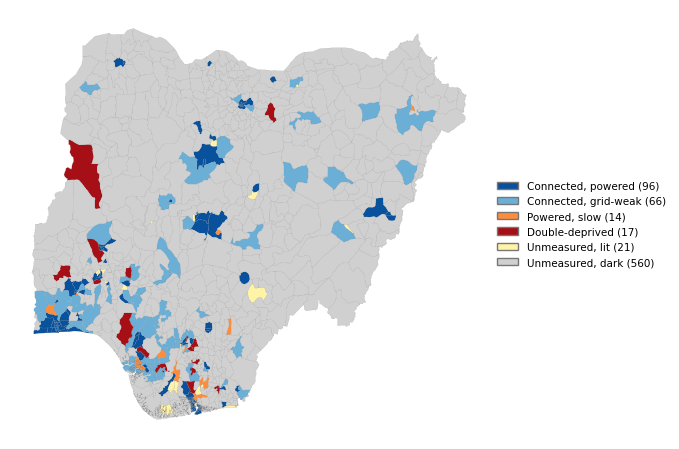

Saved: /content/drive/MyDrive/digital-divide/outputs/F1_typology.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from google.colab import drive, files

drive.mount('/content/drive')
ROOT = "/content/drive/MyDrive/digital-divide"
OUTFILE = f"{ROOT}/outputs/F1_typology.png"

lga = gpd.read_file(f"{ROOT}/interim/lga_774.gpkg")
tab = pd.read_parquet(f"{ROOT}/interim/lga_table_v4.parquet")

CLASS_COL = "cls"

# lga_id is the table's index, so turn it into a normal column
tab = tab.reset_index()
first = tab.columns[0]
if first != "lga_id":
    tab = tab.rename(columns={first: "lga_id"})

lga["lga_id"] = lga["lga_id"].astype(str)
tab["lga_id"] = tab["lga_id"].astype(str)
print("ids in map layer:  ", lga["lga_id"].head(3).tolist())
print("ids in table:      ", tab["lga_id"].head(3).tolist())

g = lga.merge(tab[["lga_id", CLASS_COL]], on="lga_id", how="left")
print("rows:", len(g), "| unmatched LGAs:", g[CLASS_COL].isna().sum())

# Colour by class name
def style(name):
    n = name.lower()
    if "unmeasured" in n and "dark" in n: return ("#d0d0d0", 6)   # grey: unmeasured, dark
    if "unmeasured" in n:                 return ("#fff3a8", 5)   # pale yellow: unmeasured, lit
    if "double" in n:                     return ("#a50f15", 4)   # dark red
    if "slow" in n:                       return ("#fd8d3c", 3)   # orange
    if "grid" in n or "weak" in n:        return ("#6baed6", 2)   # light blue
    return ("#08519c", 1)                                          # dark blue: connected, powered

classes = sorted(g[CLASS_COL].dropna().unique(), key=lambda x: style(x)[1])
colour = {c: style(c)[0] for c in classes}
counts = g[CLASS_COL].value_counts()
print("\nclass counts (expect 560, 96, 66, 21, 17, 14):")
for c in classes:
    print(f"  {c}: {counts[c]}  -> {colour[c]}")

# Plot in Africa Albers equal-area
g = g.to_crs("ESRI:102022")
fig, ax = plt.subplots(figsize=(6.7, 4.6))
for c in classes:
    g[g[CLASS_COL] == c].plot(ax=ax, color=colour[c], edgecolor="#777777", linewidth=0.08)
ax.set_axis_off()
handles = [Patch(facecolor=colour[c], edgecolor="#777777", label=f"{c} ({counts[c]})") for c in classes]
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=7.5)
plt.tight_layout()
plt.savefig(OUTFILE, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved:", OUTFILE)
files.download(OUTFILE)